# Project Milestone One: Form Your Team, Understand the Problem, and Explore the Data

#### **Due:** July 12th @ 11:59 PM (with a 2 hour & 1 minute grace period)

#### **Important:** There is **no late period** for this assignment, as manual grading must begin immediately after the deadline.

## What You Will Do in This Milestone

1. Form your project team and complete the **Team Contract** (available in the Homework Repository). Submit one copy to Gradescope.
2. Select a **team leader**, who will submit this notebook on behalf of the team after everyone has contributed to the assignment. This <a href=https://guides.gradescope.com/hc/en-us/articles/21863861823373-Adding-Group-Members-to-a-Submission>Gradescope guide</a> explains how to add group members to a submission.
3. After completing this milestone, **each team member** must complete an **Individual Team Evaluation** (available in the Homework Repository) and submit it individually to Gradescope.
4. Complete a simplified version of the **Machine Learning Project Checklist** from Appendix A of *Hands-On Machine Learning* (p. 779):

> **Part 1:** Frame the problem and understand the project goals   
> **Part 2:** Explore and understand the dataset   
> **Part 3:** Clean and prepare the data   
> **Part 4:** Investigate feature relationships   
> **Part 5:** Develop hypotheses for feature engineering and preprocessing

## The Dataset

All teams will work with the same dataset: a reduced version of the Zillow housing dataset used in the **Zillow Prize** competition on Kaggle in 2017 (unfortunately, the competition has long since ended!).

Your goal is to predict a property's **assessed tax value** (`taxvaluedollarcnt`) from a large collection of property characteristics. The dataset contains many of the challenges encountered in real machine learning projects, including:

* Missing values
* Potential outliers
* Redundant and highly correlated features
* Identifier variables that may not be useful for prediction
* Features that require careful interpretation before preprocessing

Unlike many educational datasets, this one has **not** been extensively preprocessed. Throughout this milestone, your objective is to understand the data, identify potential issues, and develop hypotheses about preprocessing and feature engineering. In **Milestone 2**, you will evaluate many of these ideas experimentally to determine whether they actually improve model performance.



In [22]:
# =============================
# Useful Imports
# =============================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split, 
    cross_val_score, 
    GridSearchCV, 
    RandomizedSearchCV, 
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.datasets import make_regression
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor

# Kaggle and Progress Tracking
from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



## Prelude: Download the Zillow Housing Dataset 

The code cell below will load the dataset for you.    

> **Notice that before downloading, this cell first checks whether the files already exist.** 

For a detailed description of the dataset features, please refer to  **Appendix 1** below. 


In [23]:

url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"

filename = os.path.basename(urlparse(url).path)

if not os.path.exists(filename):
    try:
        print("Downloading the file...")
        response = requests.get(url)
        response.raise_for_status()  # Raise an error for bad status codes
        with open(filename, "wb") as f:
            f.write(response.content)
        print("File downloaded successfully.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading the file: {e}")
else:
    print("File already exists. Skipping download.")

df = pd.read_csv(filename)

File already exists. Skipping download.


In [24]:
from pandas.api.types import is_numeric_dtype

# Methos to show the details of null cols and the % of null values in each cols.
def show_null_counts_features(df):
    count_nulls = df.isnull().sum()
    df_nulls = (df.isnull().mean() * 100).round(2)  
    feature_types = df.dtypes.apply(
        lambda x: 'Numeric' if is_numeric_dtype(x) else 'Categorical'
    )
    
    print(f'The dataset contains {len(df)} samples.\n')
    
    missing_cols = count_nulls[count_nulls > 0].index  
    if len(missing_cols) == 0:
        print("There are no null values in the dataset!")
        return None
    
    missing_data = pd.DataFrame({
        '# Null Values': count_nulls[missing_cols], 
        'Null %': df_nulls[missing_cols],
        'Type': feature_types[missing_cols]
    }).sort_values(by='Null %', ascending=False)
    
    # missing_data.index.name = 'Feature'
    display(missing_data)


# Method to display the count of Unique value and its % for a given feature in the dataframe
def show_unique_value_counts(df, column_name):
    if column_name not in df.columns:
        print(f"Error: Column '{column_name}' does not exist in the DataFrame.")
        return None
        
    total_samples = len(df)
    null_count = df[column_name].isnull().sum()
    non_null_count = total_samples - null_count
    
    null_pct = (null_count / total_samples * 100).round(2)
    non_null_pct = (non_null_count / total_samples * 100).round(2)
    
    counts = df[column_name].value_counts(dropna=False)
    percentages = (df[column_name].value_counts(dropna=False, normalize=True) * 100).round(2)
    summary_df = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages
    })
    summary_df.index = summary_df.index.fillna('Missing / NULL')
    summary_df.index.name = f'Unique Values ({column_name})'
    
    print(f"Non-Null Values: {non_null_count:<6} ({non_null_pct}%)")
    print(f"Null Values:     {null_count:<6} ({null_pct}%)\n")

    unique_count = df[column_name].nunique(dropna=True)
    print(f"Feature: {column_name}")
    print(f"Total Rows: {total_samples} | Distinct Non-Null Categories: {unique_count}")
    display(summary_df)


# Method to identify the categorical column in a generic way.
    # Rule 1 : Check for the count of unique value to be within 15
    # Rule 2 : contains the keyword 'id', 'fips', 'code', 'year' in the col name
    # Rule 3 : doesn't contains the keyword 'cnt', 'nbr', 'sqft', 'feet', 'id', 'fips', 'code', 'year'
def cat_columns_identifier(df):
    Unique_value_threshold = 15
    categorical_cols = []

    for col in df.columns:
        if df[col].dtype == 'object':
            categorical_cols.append(col)
            
        elif any(keyword in col.lower() for keyword in ['id', 'fips', 'code', 'year']):
            if col != 'parcelid':
                categorical_cols.append(col)
                
        elif df[col].nunique() <= Unique_value_threshold:
            exclude_keywords = ['cnt', 'nbr', 'sqft', 'feet', 'id', 'fips', 'code', 'year']
            if not any(kw in col.lower() for kw in exclude_keywords):
                categorical_cols.append(col)

    print(f"Total Categorical Columns Identified: {len(categorical_cols)}\n")
    print(categorical_cols)

    
# Method to check the % of matching values between features
def analyze_field_matching(df, fields):
    missing_fields = [f for f in fields if f not in df.columns]
    if missing_fields:
        print(f"following fields are missing from the DataFrame: {missing_fields}")
        return None
    if len(fields) < 2:
        print("Please provide at least 2 fields to compare.")
        return None

    print(f"Analyzing row-level match rates across fields: {fields}\n")
    df_inc = df[fields].copy()
    
    token = "FILL_NA"
    is_match_inc = df_inc.fillna(token).eq(df_inc.fillna(token).iloc[:, 0], axis=0).all(axis=1)
    
    total_inc = len(df_inc)
    matches_inc = is_match_inc.sum()
    non_matches_inc = total_inc - matches_inc
    
    summary_inc = pd.DataFrame({
        'Row Count': [matches_inc, non_matches_inc],
        'Percentage (%)': [
            round((matches_inc / total_inc) * 100, 2) if total_inc > 0 else 0,
            round((non_matches_inc / total_inc) * 100, 2) if total_inc > 0 else 0
        ]
    }, index=['Matching Rows', 'Non-Matching Rows'])
    summary_inc.index.name = 'Status (NULLs Included)'

    df_exc = df_inc.dropna()
    total_exc = len(df_exc)
    
    if total_exc > 0:
        is_match_exc = df_exc.eq(df_exc.iloc[:, 0], axis=0).all(axis=1)
        matches_exc = is_match_exc.sum()
        non_matches_exc = total_exc - matches_exc
    else:
        matches_exc, non_matches_exc = 0, 0

    summary_exc = pd.DataFrame({
        'Row Count': [matches_exc, non_matches_exc],
        'Percentage (%)': [
            round((matches_exc / total_exc) * 100, 2) if total_exc > 0 else 0,
            round((non_matches_exc / total_exc) * 100, 2) if total_exc > 0 else 0
        ]
    }, index=['Matching Rows', 'Non-Matching Rows'])
    summary_exc.index.name = 'Status (NULLs Excluded)'

    print(f"Analysis with Null Values included (Total Rows: {total_inc})")
    display(summary_inc)
    
    print(f"Analysis with Null Values excluded (Total Rows : {total_exc})")
    print(f"Note: Removed {total_inc - total_exc} rows because they contained at least one missing value.")
    display(summary_exc)

impute_cols = [
        'fireplacecnt', 
        'poolcnt', 
        'garagecarcnt', 
        'hashottuborspa', 
        'pooltypeid7', 
        'threequarterbathnbr',
        'numberofstories'
    ]

def identify_sparse_columns(df, null_threshold=0.75):
    missing_percentages = df.isnull().mean()
    cols_to_remove = [
        col for col in missing_percentages[missing_percentages > null_threshold].index
        if col not in impute_cols
    ]    
    return cols_to_remove

def remove_incomplete_samples(df, row_null_threshold=0.50):
    row_missing_pct = df.isnull().mean(axis=1)
    df_filtered_rows = df[row_missing_pct <= row_null_threshold]
    
    dropped_count = len(df) - len(df_filtered_rows)
    print(f"Dropped {dropped_count} rows with more than {row_null_threshold*100}% missing features.")
    
    return df_filtered_rows

def check_outliers_iqr(df, columns):
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr
        
        # Count outliers
        outliers = df[(df[col] < lower_fence) | (df[col] > upper_fence)]
        pct_outliers = (len(outliers) / len(df)) * 100
        
        print(f"Feature: '{col}'")
        print(f"  -> Bounds: [{lower_fence:,.2f} to {upper_fence:,.2f}]")
        print(f"  -> Outlier Count: {len(outliers)} samples ({pct_outliers:.2f}% of data)\n")

## Part 1: Frame the problem and look at the big picture [3 pts]

This part is a bit vague, since this project is not taking place in an actual business, but for the sake of exercising all the steps, **pretend** that you are working at Zillow as a data analyst and are given this dataset and asked to
- Analyze and understand the data; 
- Develop a regression model;
- Give a presentation to the marketing team about your results.  

#### **1 Discussion:** 

AFTER doing your EDA, come back and answer each of the following 3 questions in a *concise and informative paragraph between the lines;* you may wish to use your own business or home-buying experience, or to do some online research about the issues before you propose your ideas. (Don't stress about this, but *humor your professor and give it your best shot!*)


**1.1:**  What is the objective of this project in business terms?

> The business is interested in acquiring property in Southern California to exapand operations. It wants to predict the on going tax liability for each property after its acquisition to see if the potential revenue generated from the property will created lead to the desired levels of profit after expenses of the property are subtracted, of which taxes is one such expense. A property's tax liabiliity is a function of the assessed tax value. A model will be generated to predict a properties assessed tax value. 


**1.2:**  How will your solution be used?

> The properties predicted assessed tax value will then be used to analyze the feasibility of acquiring the property of interest and how the revenue generated may or may not cover expected taxes.  

**1.3:**  How should success (or failure) be measured?

> Ultimately the success or failure will be determined by a new properties profitability. A property acquirred off the model's basis would be considered a success if profits are suffiently high after accounting for tax, a function of a properies assessed value. 

## Part 2: Download and perform preliminary exploration of the data [4 pts]

### Part 2.A: Load the data into a dataframe and study each feature/column and its characteristics:
- Feature Name
- Type (categorical, int/float, text, etc.)
- Apparent usefulness for the task
- Approximate % of missing values
- How many unique values

**Note:** The **target** is the last column `'taxvaluedollarcnt'` -- pay particular attention to this during the EDA process. 
  
Hint: Just use `.head()`, `.info()`, and `.nunique()`.

In [25]:
# Drop any row that has null value on the target variable from the original dataset.
df.dropna(subset=["taxvaluedollarcnt"], inplace=True)

print(df.info())

print("A sample of 10 rows to view the data")
print(display(df.sample(10)))

print("\nFeature names from the zillow dataset")
print(df.columns)

# Categorical features
cat_cols = df.select_dtypes(exclude=["number"]).columns.tolist()
print(f"\nTotal Categorical features : {len(cat_cols)}")
print(cat_cols)

# Numeric features (everything that isn’t object / category)
num_cols = df.select_dtypes(include=["number"]).columns
print(f"\nTotal Numerical features : {len(num_cols)}")
print(num_cols)

# Method to formulate the count of null values and its % for each feature
print("\nCount of null values / percentage in each feature")
show_null_counts_features(df)

# Show the count of Unique values across each feature
print("\nUnique value count for each feature")
df.nunique().sort_values(ascending=False)

<class 'pandas.core.frame.DataFrame'>
Index: 77578 entries, 0 to 77612
Data columns (total 55 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   parcelid                      77578 non-null  int64  
 1   airconditioningtypeid         25007 non-null  float64
 2   architecturalstyletypeid      207 non-null    float64
 3   basementsqft                  50 non-null     float64
 4   bathroomcnt                   77578 non-null  float64
 5   bedroomcnt                    77578 non-null  float64
 6   buildingclasstypeid           15 non-null     float64
 7   buildingqualitytypeid         49809 non-null  float64
 8   calculatedbathnbr             76962 non-null  float64
 9   decktypeid                    614 non-null    float64
 10  finishedfloor1squarefeet      6037 non-null   float64
 11  calculatedfinishedsquarefeet  77377 non-null  float64
 12  finishedsquarefeet12          73922 non-null  float64
 13  finish

,parcelid,airconditioningtypeid,architecturalstyletypeid,basementsqft,bathroomcnt,bedroomcnt,buildingclasstypeid,buildingqualitytypeid,calculatedbathnbr,decktypeid,...,yardbuildingsqft17,yardbuildingsqft26,yearbuilt,numberofstories,fireplaceflag,assessmentyear,taxdelinquencyflag,taxdelinquencyyear,censustractandblock,taxvaluedollarcnt
9295,14321287,13.0,NaN,NaN,2.0,2.0,NaN,NaN,2.0,NaN,...,NaN,NaN,1979.0,2.0,NaN,2016.0,NaN,NaN,6.059063e+13,446290.0
22485,14467850,NaN,NaN,NaN,2.5,4.0,NaN,NaN,2.5,NaN,...,NaN,NaN,1997.0,NaN,NaN,2016.0,NaN,NaN,6.059032e+13,332616.0
7067,10996821,NaN,NaN,NaN,2.0,2.0,NaN,4.0,2.0,NaN,...,NaN,NaN,1921.0,NaN,NaN,2016.0,NaN,NaN,6.037103e+13,253246.0
11301,12750683,NaN,NaN,NaN,2.0,4.0,NaN,6.0,2.0,NaN,...,NaN,NaN,1955.0,NaN,NaN,2016.0,NaN,NaN,6.037504e+13,87318.0
30080,14188056,NaN,NaN,NaN,1.0,2.0,NaN,NaN,1.0,NaN,...,NaN,NaN,1906.0,1.0,NaN,2016.0,NaN,NaN,6.059012e+13,89052.0
63796,14149859,NaN,NaN,NaN,3.0,4.0,NaN,NaN,3.0,NaN,...,NaN,NaN,1964.0,2.0,NaN,2016.0,NaN,NaN,6.059002e+13,664988.0
65638,12222610,NaN,NaN,NaN,1.0,2.0,NaN,4.0,1.0,NaN,...,NaN,NaN,1927.0,NaN,NaN,2016.0,NaN,NaN,6.037240e+13,156244.0
45516,11556773,NaN,NaN,NaN,1.0,2.0,NaN,6.0,1.0,NaN,...,NaN,NaN,1939.0,NaN,NaN,2016.0,NaN,NaN,6.037272e+13,890558.0
25801,12156795,NaN,NaN,NaN,2.0,2.0,NaN,6.0,2.0,NaN,...,NaN,NaN,1948.0,NaN,NaN,2016.0,NaN,NaN,6.037461e+13,872323.0
55336,11939265,1.0,NaN,NaN,3.0,3.0,NaN,8.0,3.0,NaN,...,NaN,NaN,2008.0,NaN,NaN,2016.0,NaN,NaN,6.037197e+13,503470.0


None

Feature names from the zillow dataset
Index(['parcelid', 'airconditioningtypeid', 'architecturalstyletypeid',
       'basementsqft', 'bathroomcnt', 'bedroomcnt', 'buildingclasstypeid',
       'buildingqualitytypeid', 'calculatedbathnbr', 'decktypeid',
       'finishedfloor1squarefeet', 'calculatedfinishedsquarefeet',
       'finishedsquarefeet12', 'finishedsquarefeet13', 'finishedsquarefeet15',
       'finishedsquarefeet50', 'finishedsquarefeet6', 'fips', 'fireplacecnt',
       'fullbathcnt', 'garagecarcnt', 'garagetotalsqft', 'hashottuborspa',
       'heatingorsystemtypeid', 'latitude', 'longitude', 'lotsizesquarefeet',
       'poolcnt', 'poolsizesum', 'pooltypeid10', 'pooltypeid2', 'pooltypeid7',
       'propertycountylandusecode', 'propertylandusetypeid',
       'propertyzoningdesc', 'rawcensustractandblock', 'regionidcity',
       'regionidcounty', 'regionidneighborhood', 'regionidzip', 'roomcnt',
       'storytypeid', 'threequarterbathnbr', 'typeconstructiontypeid',
       '

,# Null Values,Null %,Type
buildingclasstypeid,77563,99.98,Numeric
finishedsquarefeet13,77536,99.95,Numeric
storytypeid,77528,99.94,Numeric
basementsqft,77528,99.94,Numeric
yardbuildingsqft26,77508,99.91,Numeric
fireplaceflag,77406,99.78,Categorical
architecturalstyletypeid,77371,99.73,Numeric
typeconstructiontypeid,77355,99.71,Numeric
finishedsquarefeet6,77192,99.50,Numeric
pooltypeid10,77113,99.40,Numeric



Unique value count for each feature


parcelid                        77380
latitude                        64037
longitude                       62460
taxvaluedollarcnt               50949
rawcensustractandblock          39188
censustractandblock             39006
lotsizesquarefeet               18848
calculatedfinishedsquarefeet     4972
finishedsquarefeet12             4868
propertyzoningdesc               1907
finishedsquarefeet50             1807
finishedfloor1squarefeet         1787
finishedsquarefeet15             1724
garagetotalsqft                   839
yardbuildingsqft17                540
regionidneighborhood              480
regionidzip                       389
finishedsquarefeet6               350
poolsizesum                       262
regionidcity                      175
yearbuilt                         136
propertycountylandusecode          75
yardbuildingsqft26                 59
basementsqft                       43
bathroomcnt                        22
calculatedbathnbr                  21
bedroomcnt  

#### **2.A Discussion:** 

Answer the following questions. You may wish to examine Appendix 3 before starting. 

**2.A.1:**  Which features are categorical?

> These are the explicit categorical features **hashottuborspa, propertycountylandusecode, propertyzoningdesc, fireplaceflag, taxdelinquencyflag** as per the dataset. However, several numerical features representing categories, such as **airconditioningtypeid, propertylandusetypeid, heatingorsystemtypeid and the regionid fields** should also be treated as categorical columns.

> In short, all 25 of these features can be considered categorical columns based on the logic defined in the **cat_columns_identifier** function **'airconditioningtypeid', 'architecturalstyletypeid', 'buildingclasstypeid', 'buildingqualitytypeid', 'decktypeid', 'fips', 'hashottuborspa', 'heatingorsystemtypeid', 'pooltypeid10', 'pooltypeid2', 'pooltypeid7', 'propertycountylandusecode', 'propertylandusetypeid', 'regionidcity', 'regionidcounty', 'regionidneighborhood', 'regionidzip', 'storytypeid', 'typeconstructiontypeid', 'yearbuilt', 'numberofstories', 'fireplaceflag', 'assessmentyear', 'taxdelinquencyflag', 'taxdelinquencyyear'**

**2.A.2:**  Are there any features which appear at first glance to be **useless** for the business purpose of this project and should be deleted?  Give examples and describe your reasoning briefly. 

> At first glance, these are some of the features seem **useless** :
> * **parcelid** - Represents a unique identifer for the property, most likely as a primary key
> * **calculatedbathnbr** - Appears to be a redundant duplicate of the **bathroomcnt** field
> * **finishedsquarefeet12** - Appears to be a minor variation or duplicate of **calculatedfinishedsquarefeet**.

**2.A.3:**  Are there any features which appear to be **useless** because of the percentage of missing values?  If so, give an example. 

> These are some of the features seems to be **useless** based on the high % of missing values
> * **buildingclasstypeid** (99.9% missing)
> * **finishedsquarefeet13** (99.9% missing)
> * **basementsqft** (99.9% missing)
> * **storytypeid** (99.9% missing)
> * **yardbuildingsqft26** (99.9% missing)
> * **architecturalstyletypeid** (99.7% missing)
> * **typeconstructiontypeid** (99.7% missing)

**2.A.4:**  Are there any features which appear to be **useless** because of the number of unique values?  If so, give an example. 

> **assessmentyear** is the ONLY field that appears to be useless based on its number of unique values. It contains only a single unique value (2016), meaning it acts as a constant with zero variance.

### Part 2.B: Exploratory Data Analysis (EDA) -- Feature-Level Visualization  

- To get an overview, generate histograms for all features using `df.hist()`  (Hint: increase the figsize and set the layout to `(-1,m)` to get  `m` columns and as many rows as necessary.)
- Generate individual visualizations for the target and three (3) additional features that you believe are particularly informative or interesting (a total of four features): 
    - Use appropriate plot types (e.g., histograms and boxplots for numerical features, bar plots for categorical features) to understand distributions and identify potential outliers for these three.
    - Use as many code cells as you need, and give comments describing what each cell does.
    - Answer the discussion question posed (you should choose 3 features for which you can say something interesting in the discussion).  

array([[<Axes: title={'center': 'parcelid'}>,
        <Axes: title={'center': 'airconditioningtypeid'}>,
        <Axes: title={'center': 'architecturalstyletypeid'}>,
        <Axes: title={'center': 'basementsqft'}>],
       [<Axes: title={'center': 'bathroomcnt'}>,
        <Axes: title={'center': 'bedroomcnt'}>,
        <Axes: title={'center': 'buildingclasstypeid'}>,
        <Axes: title={'center': 'buildingqualitytypeid'}>],
       [<Axes: title={'center': 'calculatedbathnbr'}>,
        <Axes: title={'center': 'decktypeid'}>,
        <Axes: title={'center': 'finishedfloor1squarefeet'}>,
        <Axes: title={'center': 'calculatedfinishedsquarefeet'}>],
       [<Axes: title={'center': 'finishedsquarefeet12'}>,
        <Axes: title={'center': 'finishedsquarefeet13'}>,
        <Axes: title={'center': 'finishedsquarefeet15'}>,
        <Axes: title={'center': 'finishedsquarefeet50'}>],
       [<Axes: title={'center': 'finishedsquarefeet6'}>,
        <Axes: title={'center': 'fips'}>,
    

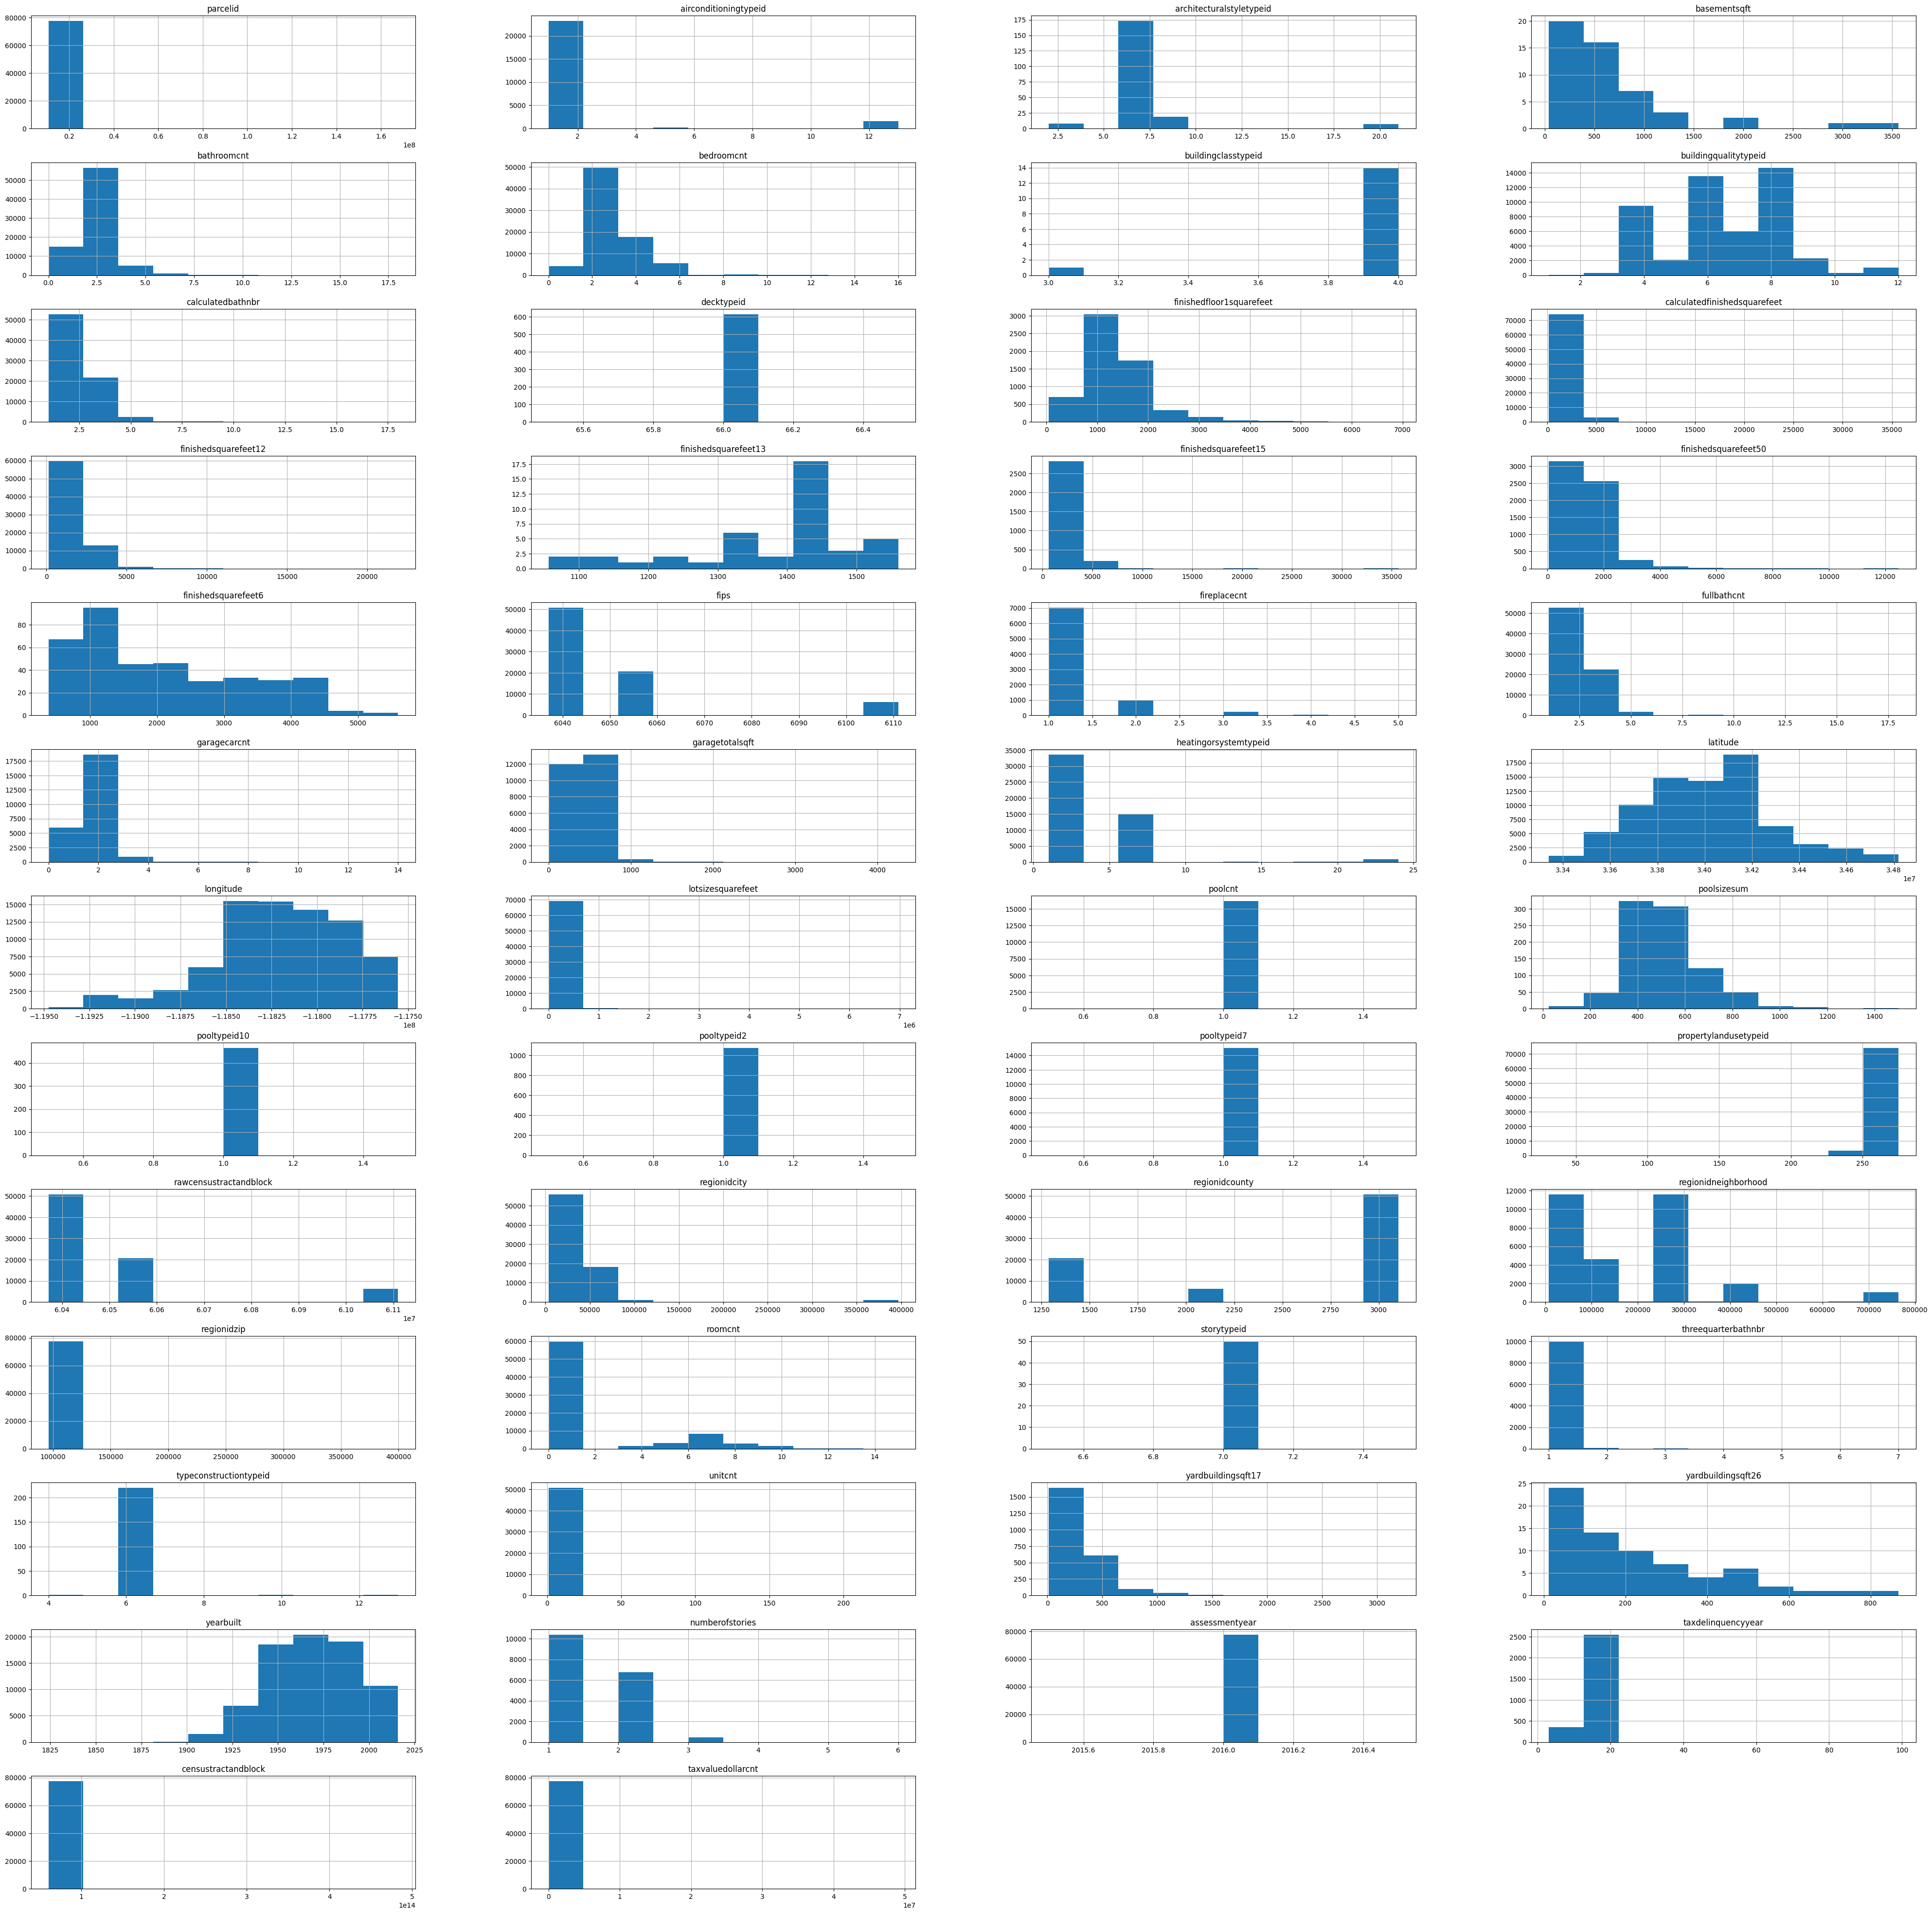

In [26]:
df.hist(figsize=(50,50), layout=(-1,4))

count       77578.000000
mean       490150.588891
std        653797.859628
min          1000.000000
25%        206898.500000
50%        358878.500000
75%        569000.000000
max      49061236.000000
Name: taxvaluedollarcnt, dtype: object


Text(0.5, 0.98, 'Distribution of Target Value, Accessed Tax Value')

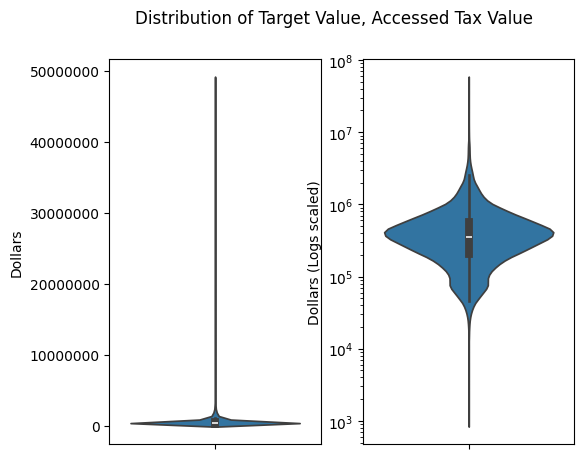

In [27]:
#Distribution of Target Value, Accessed Tax Value (taxvaluedollarcnt). Violin plot has a log scaled axis such that the plot can be interpreted with the major outliers
fig, ax = plt.subplots(1,2)
sns.violinplot(df['taxvaluedollarcnt'],log_scale=10, ax=ax[1])
ax[1].set_ylabel('Dollars (Logs scaled)')
print(df['taxvaluedollarcnt'].describe().apply(lambda x: format(x, 'f')))
sns.violinplot(df['taxvaluedollarcnt'], ax=ax[0], )
ax[0].set_ylabel('Dollars')
ax[0].ticklabel_format(style = 'plain', axis = 'y')
fig.set_size_inches(6,5)
fig.suptitle('Distribution of Target Value, Accessed Tax Value')

count    77377.000000
mean      1784.943019
std        954.254198
min        128.000000
25%       1182.000000
50%       1542.000000
75%       2112.000000
max      35640.000000
Name: calculatedfinishedsquarefeet, dtype: object


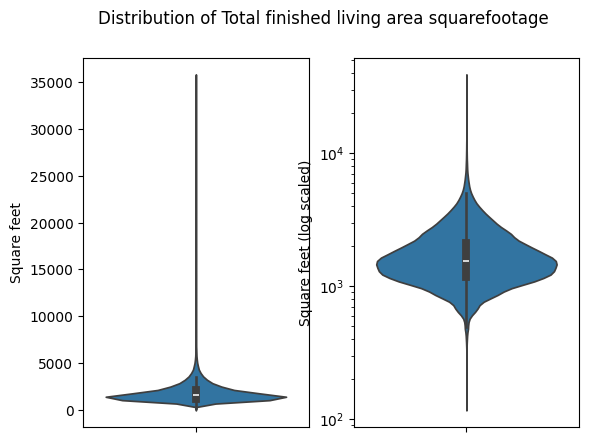

In [28]:
#Distribution of Finished living area squarefootage.
fig, ax  = plt.subplots(1,2)
sns.violinplot(df['calculatedfinishedsquarefeet'], ax= ax[0])
fig.suptitle('Distribution of Total finished living area squarefootage')
ax[0].set_ylabel('Square feet')
sns.violinplot(df['calculatedfinishedsquarefeet'], ax= ax[1], log_scale=10)
ax[1].set_ylabel('Square feet (log scaled)')

print(df['calculatedfinishedsquarefeet'].describe().apply(lambda x: format(x, 'f')))

count      69320.000000
mean       29973.765392
std       123305.907773
min          236.000000
25%         5700.000000
50%         7206.000000
75%        11837.000000
max      6971010.000000
Name: lotsizesquarefeet, dtype: object


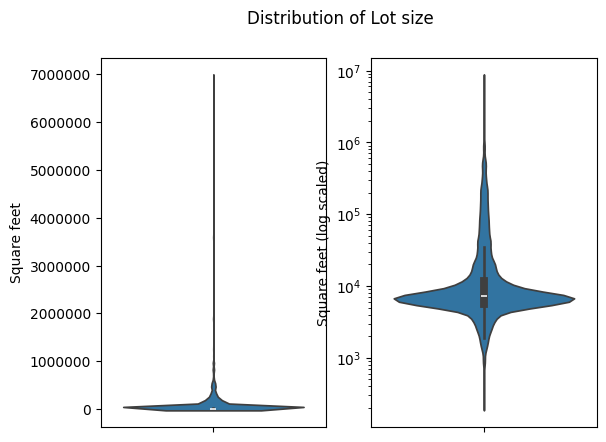

In [29]:
#Distribution of Lot size (square footage).
fig, ax  = plt.subplots(1,2)
sns.violinplot(df['lotsizesquarefeet'], ax=ax[0])

sns.violinplot(df['lotsizesquarefeet'], log_scale=10, ax= ax[1])
fig.suptitle('Distribution of Lot size')
ax[0].set_ylabel('Square feet')
ax[0].ticklabel_format(style = 'plain', axis = 'y')

ax[1].set_ylabel('Square feet (log scaled)')

print(df['lotsizesquarefeet'].describe().apply(lambda x: format(x, 'f')))

Latitude distribution
count     0.077578
mean     34.008372
std       0.265288
min      33.339527
25%      33.814635
50%      34.022000
75%      34.174313
max      34.818767
Name: latitude, dtype: float64


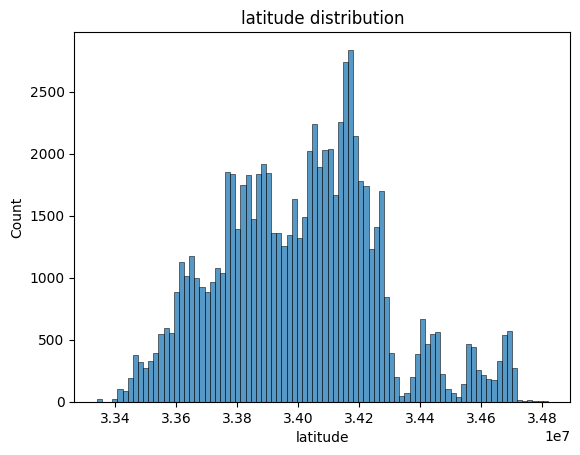

Longitude distribution
count      0.077578
mean    -118.203736
std        0.359410
min     -119.475416
25%     -118.415010
50%     -118.181000
75%     -117.928640
max     -117.554636
Name: longitude, dtype: float64


Text(0.5, 1.0, 'longitude distribution')

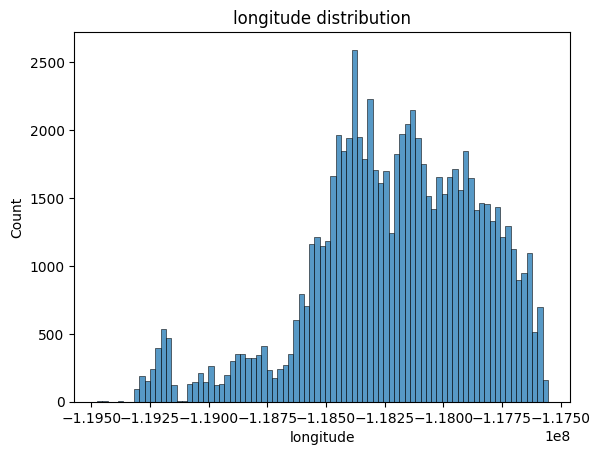

In [30]:
print('Latitude distribution')
print(df['latitude'].describe().apply(lambda x: x/1000000))
sns.histplot(x= df['latitude'], cbar=True)
plt.title("latitude distribution")
plt.show()
print('Longitude distribution')
print(df['longitude'].describe().apply(lambda x: x/1000000))
sns.histplot(x= df['longitude'], cbar=True)
plt.title("longitude distribution")

Text(0.5, 1.0, 'Home location')

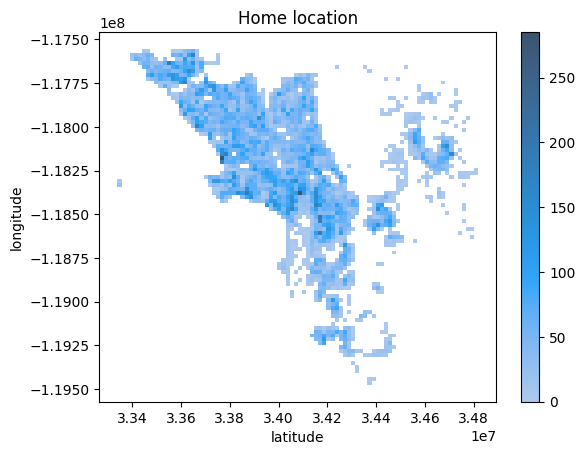

In [31]:
sns.histplot(x= df['latitude'],y=df['longitude'], cbar=True)
plt.title('Home location')

#### **2.B Discussion:** 

Describe what you learned from your detailed examination of the four features you selected. For each feature, discuss:

- The overall distribution (for example, approximately normal, skewed, or multimodal).
- Any notable characteristics, such as outliers, unusual values, or missing data.
- Why you selected the feature and what you learned about the dataset from examining it.

Conclude by briefly discussing whether any of the features you examined might require additional preprocessing later in the project (such as imputation, transformation, or outlier investigation).

> Accessed Tax Value - Target Variable
> Understanding the behavior of the target variable, tax accessed value of a property, is crucial to being able to build a model for that target variable. The variable is highly right skewed. The maximum value is $49,061,236 which is almost 100 greater than the 75th percentile of the data, $569,000. The target variable had an IQR of $362,101.

> Total finished living area (square foot)
> One of the key features of a property, is the what the living area. The price of a small house differs greatly from the price of a large house. Finished living area square ft is also right skewed. There are many values higher than the median. The IQR of this distribution is 930 sqft, mean of 1542 sqft. The maximum value is 35,560 sqft. 

> Lot Size
> Similarily to how a homes living area, the value of a property can be tied to its size. The distribution of the lot sizes is once again highly right skewed. The data had a mean of 7206 sqft, IQR of 6137 sqft, and maximum value of 6,971,010 sqft. 

> Latitude and Longitude
> In real estate, location of a property is often cited as a properties most important aspect, as it is one of the few things you cannot change at all. Histograms show us that the data is not a standard distrubution, for both latitude and longitude. This makes sense as the places people make homes are not random. Land is not alwasy hospitable, and cities have more homes due to density. Plotting a 2D histogram reveals the locations of the homes to be southern California. 



## Part 3:  Clean the Data: Drop, Impute, and Encode [6 pts]



**Important Notes:**
- You should review your Homework 4 before doing this section!
- Create new names for modified data at each stage to avoid problems with global variables.
- Whenever possible, write functions for all data transformations you apply, for these reasons:
    - So you can easily prepare the data the next time you get a fresh dataset
    - So you can apply these transformations in future projects
    - To clean and prepare new data instances once your solution is live
    - To make it easy to treat your preparation choices as hyperparameters
    - [To apply the same transformations to your test set if train/test split already done -- not applicable here]

### Part 3.A: Drop features you judge to be unsuitable for the regression task

Your call, based on any research you can do to understand the feature (hopefully IRL you would have a domain expert to help with this, but do your best).   

Note: Do not drop features because of too many missing values, that's the next task! 

In [32]:
drop_cols = [
    'parcelid', 
    'calculatedbathnbr', 
    'finishedsquarefeet12', 
    'rawcensustractandblock',
    'finishedsquarefeet15'
]
df_clean = df.drop(columns=drop_cols)

#### **3.A Discussion:**

Describe the features you chose to remove, if any, and justify each decision. For each feature, explain:

- Why you believed it was unsuitable for predicting the target.
- Which characteristic led to your decision (for example, an identifier, irrelevant information, or another reason).
- Why your decision was based on the feature's meaning rather than the amount of missing data.

If you chose not to remove any features, explain why.

> * **parcelid** - As it represents a unique identifier for the property, it won't add any value for target prediction.
> * **calculatedbathnbr** - As it appears to be a redundant duplicate of the **bathroomcnt** field, it might cause multicollinearity in the target variable identification.
> * **finishedsquarefeet12** - As it is a minor variation of the **calculatedfinishedsquarefeet**, it carries severe semantic redundancy.
> * **rawcensustractandblock** - As rawcensustractandblock is the unformatted raw sting version of the **censustractandblock**, this field can be removed as it is a redudant feature
> * **finishedsquarefeet15** - As **calculatedfinishedsquarefeet** already carries the aggregated accurate square foot of the home, other variations can be removed as it might cause multicollinearity issue.

### Part 3.B: Drop **features** with "too many" null values

Your code in the next cell(s). Make a judgement call about what "too many" means and briefly describe your reasoning in the discussion.   

Note: "Too many" may depend on what the non-null values look like, be sure to investigate carefully. 

In [33]:
cols_to_drop_3B = identify_sparse_columns(df_clean, 0.75)
print(f"Columns identified for removal with too many values based on 75% threshold value ({len(cols_to_drop_3B)} total):\n")
print(cols_to_drop_3B)
df_clean.drop(columns=cols_to_drop_3B, inplace=True)

Columns identified for removal with too many values based on 75% threshold value (18 total):

['architecturalstyletypeid', 'basementsqft', 'buildingclasstypeid', 'decktypeid', 'finishedfloor1squarefeet', 'finishedsquarefeet13', 'finishedsquarefeet50', 'finishedsquarefeet6', 'poolsizesum', 'pooltypeid10', 'pooltypeid2', 'storytypeid', 'typeconstructiontypeid', 'yardbuildingsqft17', 'yardbuildingsqft26', 'fireplaceflag', 'taxdelinquencyflag', 'taxdelinquencyyear']


#### **3.B Discussion:**

Describe the criteria you used to decide which features had **too many** missing values to retain.

In particular, explain:

- The threshold you selected for determining when a feature should be removed.
- Why you believe this threshold was appropriate for this dataset.
- Whether you considered the usefulness of the remaining non-null values before deciding to remove a feature, and how this influenced your decision.

> **1. Threshold Selection & Appropriateness:**
> A threshold of 75% has been selected to flag features for removal once their missingness reaches this limit. This threshold was chosen because forcing an imputation technique onto highly sparse columns fills nearly all rows with identical placeholder values. This injects a massive block of artificial, zero-variance noise that dilutes genuine feature signals, severely reducing information gain and causing tree-based models to overfit on the tiny handful of remaining real observations.
> 
> **2. Usefulness Evaluation:**
> Key features were explicitly evaluated before blindly applying the automated threshold, taking into account the underlying real estate meaning and semantic utility of the non-null values. This evaluation resulted in two distinct feature classifications:
> 
> * **Structural Absences (Retained):** Certain features like `fireplacecnt`, `poolcnt`, and `garagecarcnt` technically exceeded the 75% missingness limit. However, a missing value (`NaN`) in these fields does not mean the data was lost or forgotten; instead, it signifies a structural zero, implying that the house simply does not possess a fireplace, pool, or garage. Because these amenities are highly valuable for pricing premium properties, we intentionally exempted them from the removal pipeline so they can be imputed with a constant `0` value and retained for model training.
> * **Uninformative Noise (Removed):** Regarding the 18 removed columns, the remaining non-null values were judged to be statistically uninformative for a macro-regression task. For example, `basementsqft` is missing 99.9% of its records because basements are structurally rare in Southern California, meaning the model cannot learn a generalized pattern from the training data. Similarly, the `decktypeid` feature contains only a single constant numerical value (`66.0`) when populated, offering zero mathematical variance. Hence, these 18 features were safely removed to prevent unnecessary dimensionality noise.

### Part 3.C: Remove Problematic Samples

Some samples may not be suitable for model training because they contain insufficient information or cannot be used for supervised learning.

- Remove any sample with a missing target value.
- Decide on a reasonable threshold for the maximum percentage of missing feature values in a sample, justify your choice, and remove samples exceeding that threshold.
- Investigate whether the dataset contains potential outliers, but **do not remove them yet.** Instead, describe how you identified them and explain why removing them may or may not be appropriate. Their effect on model performance will be investigated in Milestone 2.

Your code in the next cell(s). Make a judgement call about which samples should be dropped and briefly describe your reasoning in the discussion.   


In [34]:
df_clean.dropna(subset=["taxvaluedollarcnt"], inplace=True)
df_clean = remove_incomplete_samples(df_clean, 0.50)

# Run the diagnostic scanner on continuous variables
continuous_vars = ['taxvaluedollarcnt', 'calculatedfinishedsquarefeet', 'lotsizesquarefeet']
check_outliers_iqr(df_clean, continuous_vars)

print("--- Discrete Feature Range Analysis ---")
discrete_vars = ['bedroomcnt', 'bathroomcnt', 'garagecarcnt']
for col in discrete_vars:
    print(f"\nFeature '{col}':")
    print(f"  -> Minimum value found: {df_clean[col].min()}")
    print(f"  -> Maximum value found: {df_clean[col].max()}")
    print(f"  -> Top 3 highest values:\n{df_clean[col].value_counts().sort_index().tail(3)}\n")

Dropped 136 rows with more than 50.0% missing features.
Feature: 'taxvaluedollarcnt'
  -> Bounds: [-335,834.62 to 1,111,724.38]
  -> Outlier Count: 5155 samples (6.66% of data)

Feature: 'calculatedfinishedsquarefeet'
  -> Bounds: [-213.00 to 3,507.00]
  -> Outlier Count: 4006 samples (5.17% of data)

Feature: 'lotsizesquarefeet'
  -> Bounds: [-3,481.50 to 21,002.50]
  -> Outlier Count: 11402 samples (14.72% of data)

--- Discrete Feature Range Analysis ---

Feature 'bedroomcnt':
  -> Minimum value found: 0.0
  -> Maximum value found: 16.0
  -> Top 3 highest values:
bedroomcnt
13.0    2
14.0    1
16.0    1
Name: count, dtype: int64


Feature 'bathroomcnt':
  -> Minimum value found: 0.0
  -> Maximum value found: 18.0
  -> Top 3 highest values:
bathroomcnt
11.0    3
13.0    1
18.0    1
Name: count, dtype: int64


Feature 'garagecarcnt':
  -> Minimum value found: 0.0
  -> Maximum value found: 14.0
  -> Top 3 highest values:
garagecarcnt
11.0    1
13.0    1
14.0    1
Name: count, dtype: in

#### **3.C Discussion:**

Describe your decisions about which samples were removed and why.

In particular, discuss:

- The criteria you used to identify samples that should be removed (for example, missing target values or excessive missing data).
- If you identified potential outliers, explain how you identified them and why you chose to retain them at this stage.
- The potential advantages and disadvantages of removing outliers, and why you believe this decision should be evaluated experimentally in **Milestone 2**.

> > **3.C Discussion:**
> 
> **Missing Target Samples:**
> Any samples missing the target variable (`taxvaluedollarcnt`) were dropped instantly as those unlabelled samples cannot contribute to a meaningful supervised regression model.
> 
> **Row-Level Threshold:**
> We have implemented a feature missingness threshold of 50% to flag samples for deletion. Having more than 50% of missing features could cause incomplete vectors that can provide insufficient physical context for tree-splitting optimizations.
> 
> **Outlier Investigation:**
> Implemented the statistical IQR bounding technique to determine the potential outlier on the primary continous variables (`taxvaluedollarcnt`, `calculatedfinishedsquarefeet`, and `lotsizesquarefeet`) to determine the exact volume of extreme outliers. Concurrently, a logical range difference was evaluated on discrete features (`bedroomcnt`, `bathroomcnt`, and `garagecarcnt`) to audit maximum and minimum bounds for any impossible values.

> These outliers are still retained as per the guidelines for further investigation in Milestone 2

### Part 3.D: Split the Dataset into Training and Test Sets

Now that the initial data cleaning is complete, split the dataset into training and test sets.

Use:

- test_size=0.20
- random_state=42

The remaining preprocessing steps should be learned **only from the training set** and then applied unchanged to the test set. This prevents information from the test set from influencing the training process ("data leakage"). 

No discussion necessary. 

In [35]:
df_clean.reset_index(drop=True, inplace=True)

X = df_clean.drop(columns="taxvaluedollarcnt")
y = df_clean["taxvaluedollarcnt"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (61953, 31)
Testing features shape: (15489, 31)
Training target shape: (61953,)
Testing target shape: (15489,)


### Part 3.E: Impute for the remaining missing values

Review the methods for imputation in **Appendix 2** and choose how you will impute the remainder of the missing values. Note:
- Consider whether different methods are justified for different features.
- In the next cells, apply your imputation methods to the dataset so that no null values remain after this step.
- Fit your imputation method(s) using only the training data.
- Apply the fitted imputer(s) to both the training and test sets so that no missing values remain.
- Answer the discussion question.


In [36]:
zero_impute_cols = ['fireplacecnt', 'poolcnt', 'garagecarcnt', 'threequarterbathnbr', 'numberofstories','pooltypeid7','airconditioningtypeid']
false_impute_cols = ['hashottuborspa']
median_imputer_cols = ['yearbuilt', 'buildingqualitytypeid', 'lotsizesquarefeet', 'calculatedfinishedsquarefeet', 'censustractandblock']
unknown_imputer_cols = ['regionidneighborhood']
most_freq_imputer_cols = ['heatingorsystemtypeid', 'regionidcity', 'regionidzip']

garage_active_median = X_train.loc[X_train['garagecarcnt'] > 0, 'garagetotalsqft'].median()

# Zero constant Imputer
X_train[zero_impute_cols] = X_train[zero_impute_cols].fillna(0)
X_test[zero_impute_cols] = X_test[zero_impute_cols].fillna(0)

# Number 1.0 constant Imputer
X_train['unitcnt'] = X_train['unitcnt'].fillna(1.0)
X_test['unitcnt'] = X_test['unitcnt'].fillna(1.0)

# Unknown Imputer, Replace with a value of -1
X_train[unknown_imputer_cols] = X_train[unknown_imputer_cols].fillna(-1)
X_test[unknown_imputer_cols] = X_test[unknown_imputer_cols].fillna(-1)

# Unknown Imputer for Categorical feature propertyzoningdesc, Replace with a value of 'Unknown'
X_train['propertyzoningdesc'] = X_train['propertyzoningdesc'].fillna('Unknown')
X_test['propertyzoningdesc'] = X_test['propertyzoningdesc'].fillna('Unknown')

# Impute fullbathcnt with bathroomcnt value
X_train['fullbathcnt'] = X_train['fullbathcnt'].fillna(X_train['bathroomcnt'])
X_test['fullbathcnt'] = X_test['fullbathcnt'].fillna(X_test['bathroomcnt'])

X_train.loc[X_train['garagecarcnt'] == 0, 'garagetotalsqft'] = X_train.loc[X_train['garagecarcnt'] == 0, 'garagetotalsqft'].fillna(0.0)
X_test.loc[X_test['garagecarcnt'] == 0, 'garagetotalsqft'] = X_test.loc[X_test['garagecarcnt'] == 0, 'garagetotalsqft'].fillna(0.0)
X_train.loc[X_train['garagecarcnt'] > 0, 'garagetotalsqft'] = X_train.loc[X_train['garagecarcnt'] > 0, 'garagetotalsqft'].fillna(garage_active_median)
X_test.loc[X_test['garagecarcnt'] > 0, 'garagetotalsqft'] = X_test.loc[X_test['garagecarcnt'] > 0, 'garagetotalsqft'].fillna(garage_active_median)

# Apply constant False to the hot tub boolean flag
X_train[false_impute_cols] = X_train[false_impute_cols].fillna(False)
X_test[false_impute_cols] = X_test[false_impute_cols].fillna(False)

# Median Imputer Logic
median_imputer = SimpleImputer(strategy='median')
X_train[median_imputer_cols] = median_imputer.fit_transform(X_train[median_imputer_cols])
X_test[median_imputer_cols] = median_imputer.transform(X_test[median_imputer_cols])

# Most Frequent Imputer Logic
most_freq_imputer = SimpleImputer(strategy='most_frequent')
X_train[most_freq_imputer_cols] = most_freq_imputer.fit_transform(X_train[most_freq_imputer_cols])
X_test[most_freq_imputer_cols] = most_freq_imputer.transform(X_test[most_freq_imputer_cols])

show_null_counts_features(X_train)
show_null_counts_features(X_test)

The dataset contains 61953 samples.

There are no null values in the dataset!
The dataset contains 15489 samples.

There are no null values in the dataset!


C:\Users\kcahp\AppData\Local\Temp\ipykernel_38720\911937478.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[false_impute_cols] = X_train[false_impute_cols].fillna(False)
C:\Users\kcahp\AppData\Local\Temp\ipykernel_38720\911937478.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[false_impute_cols] = X_test[false_impute_cols].fillna(False)


#### **3.E Discussion:**

Describe your overall imputation strategy.

In particular, explain:

- Which imputation method(s) you selected.
- Why each method was appropriate for the feature(s) to which it was applied.
- Whether you used different strategies for different types of features (for example, numerical versus categorical, or approximately normal versus skewed numerical features), and why.

> **Constant Zero & False Imputation:** Features like `fireplacecnt`, `poolcnt`, `pooltypeid7`, `garagecarcnt`, `threequarterbathnbr`, `numberofstories`, `airconditioningtypeid`, and `hashottuborspa` that were missing values or counts of non-standard amenities do not represent administrative errors. Instead, missingness indicates the structural absence of that amenity in the home (e.g., no pool, no AC, or no garage). Imputing with a constant value of `0` (or `False` for the boolean flag) helps tree models rely on true structural distribution properties.

> **Single-Family Unit (Constant 1.0 Imputation):** For the `unitcnt` feature, **NaN** simply indicates that the structure is a single-family home where tax assessors left the field intentionally blank instead of filling it with `1.0`. Imputing a constant `1.0` maintains accurate baseline tracking without distorting multi-family density variables.

> **"Unknown" Categorical Category:** We opted for an 'Unknown' category imputation (`-1` for spatial numerical identifiers and `'Unknown'` for textual descriptions) for the `regionidneighborhood` and `propertyzoningdesc` features. As these features exhibit heavy missingness, a `most_frequent` mode imputer could inject severe variance compression and bias over one-third of the dataset toward an arbitrary dominant group.

> **Fractional Bathrooms:** `fullbathcnt` was filled with values from `bathroomcnt` programmatically. Because `bathroomcnt` has 100% of its values filled in, it makes perfect sense to fill `fullbathcnt` with the matching baseline from the `bathroomcnt` field, which preserves the exact distribution of fractional counts (e.g., 1.5, 2.5) without rounding distortion.

> **Conditional Sizing (garagetotalsqft):** A strict, condition-based imputation technique was applied to `garagetotalsqft` based on the availability of the `garagecarcnt` feature. For homes where a garage exists (`garagecarcnt > 0`) but the square footage was missing, a median imputation strategy was followed. Conversely, for homes with a zero `garagecarcnt`, a constant value of `0.0` was imputed.

> **Median Imputation for Continuous Features:** For metric features like `yearbuilt`, `buildingqualitytypeid`, `lotsizesquarefeet`, `calculatedfinishedsquarefeet`, and `censustractandblock`, we used the `SimpleImputer` median strategy. Because real estate dimensions are often heavily right-skewed due to extreme outliers, median imputation serves as a robust central metric to keep the baseline stable.

> **Mode Imputer for Spatial Categories:** For `heatingorsystemtypeid`, `regionidcity`, and `regionidzip`, a `most_frequent` mode strategy was applied. Since these columns have nominal structures and low missingness rates, mapping the missing entries to the most dominant value maintains valid categorical syntax without distorting regional distributions.

### 3.F: Encode the Categorical Features (if any)

Refer to Appendix 3 for a summary of feature types and appropriate encoding strategies.

- Identify any categorical features that remain after your earlier preprocessing. For each feature, determine whether it is nominal or ordinal, then choose an appropriate encoding method. Use ordinal encoding only for features with a meaningful ordering, and one-hot encoding for nominal features with no natural ordering.

- Fit the encoder(s) using only the training data, then apply the fitted encoder(s) to both the training and test sets. Some teams may have very few categorical features remaining after the earlier cleaning steps.

**Note:** Many categorical features in this dataset are represented by numeric identifier codes (for example, `propertylandusetypeid`). Do not assume that a feature is numerical simply because its data type is int or float. Instead, use the feature descriptions in Appendix 1 and flowchart in Appendix 3 to determine whether the feature represents a numerical measurement or a categorical variable.

In [37]:
from sklearn.preprocessing import OneHotEncoder

print(f"# of X_train Columns before encoding: {len(X_train.columns)}")

nominal_cols = ['airconditioningtypeid', 'heatingorsystemtypeid', 'unitcnt', 'regionidcity', 'regionidzip']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_ohe = ohe.fit_transform(X_train[nominal_cols])
X_test_ohe = ohe.transform(X_test[nominal_cols])

ohe_feature_names = ohe.get_feature_names_out(nominal_cols)
X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe_feature_names, index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe_feature_names, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=nominal_cols), X_train_ohe_df], axis=1)
X_test = pd.concat([X_test.drop(columns=nominal_cols), X_test_ohe_df], axis=1)

print(f"Final Preprocessed X_train shape: {X_train.shape}")
print(f"Final Preprocessed X_test shape:  {X_test.shape}")
print(f"Total remaining missing values: {X_train.isnull().sum().sum()}")
print(f"# of X_train Columns after encoding: {len(X_train.columns)}")
print(f"# of X_test Columns after encoding: {len(X_test.columns)}")

# of X_train Columns before encoding: 31


Final Preprocessed X_train shape: (61953, 611)
Final Preprocessed X_test shape:  (15489, 611)
Total remaining missing values: 0
# of X_train Columns after encoding: 611
# of X_test Columns after encoding: 611


#### **3.F Discussion:**

Describe the categorical features that remained after your earlier preprocessing.

In particular, discuss:

- Which features you identified as categorical.
- Whether each feature is **nominal** or **ordinal**, and why.
- The encoding method you selected for each feature and why it was appropriate.
- At least one feature that is represented by a numeric identifier rather than text, explaining why it is still categorical and how this influenced your encoding decision.

> **Categorical Features :** The categorical and discrete properties remaining in our featureset that are eligible for encoding includes `airconditioningtypeid`, `heatingorsystemtypeid`, `unitcnt`, `regionidcity`, `regionidzip`, `buildingqualitytypeid`, `regionidneighborhood`, and `propertyzoningdesc`.

> **Nominal vs. Ordinal Encoding Decisions:**
  * **Nominal Features (One-Hot Encoded):** `airconditioningtypeid`, `heatingorsystemtypeid`, `unitcnt`, `regionidcity`, and `regionidzip` represent pure nominal classifications with numerical data type floats. Because these identifier tracking codes possess no inherent continuous scale, leaving them as raw numbers would force the Machine learning algorithms to falsely assume meaningful order. By applying OneHotEncoder(handle_unknown='ignore'), we uncouple them into distinct binary dimensions, allowing the model to consider it as independent isolated category.
  * **Ordinal Features (Pass-Through):** As defined in the data dictionary, `buildingqualitytypeid` is defined as an overall structural assessment where higher values represent superior architectural quality. As it naturally sits on a continuous sequential scale, we pass it through as a standard numerical scalar.

> **High-Cardinality Fields:** For features such as `propertyzoningdesc` and `regionidneighborhood`, we opt to pass them through rather applying the one-hot encoding logic. Given that `propertyzoningdesc` contains nearly 2,000 distinct string values, one-hot encoding would instantly trigger a massive "curse of dimensionality" that could induce heavy model overfitting.

## Part 4: Investigate Feature Relationships [6 pts]

In this part, you will investigate relationships among the features and between the features and the target. The goal is to better understand the dataset and identify opportunities for future feature engineering.

**Important:** At this stage, you should **not** commit to any changes to the dataset based on these analyses. Many preprocessing and feature engineering decisions are model-dependent and will be evaluated experimentally in **Milestone 2**.

### Part 4.A: Correlation and Feature Importance

Investigate relationships among the features and between the features and the target.

In the next cell(s):

- Compute a **correlation matrix** for the numerical features.
- Visualize the results where appropriate (for example, a heatmap and a bar chart).
- Identify features that appear to have particularly strong or weak relationships with the target.
- Identify pairs of features that appear to be highly correlated.
- Do **not** remove or transform any features based on these analyses.

Analysis frame (cleaned training set): (61953, 612)
Using 16 true-numeric features (excluded 593 ID codes and one-hot dummies).


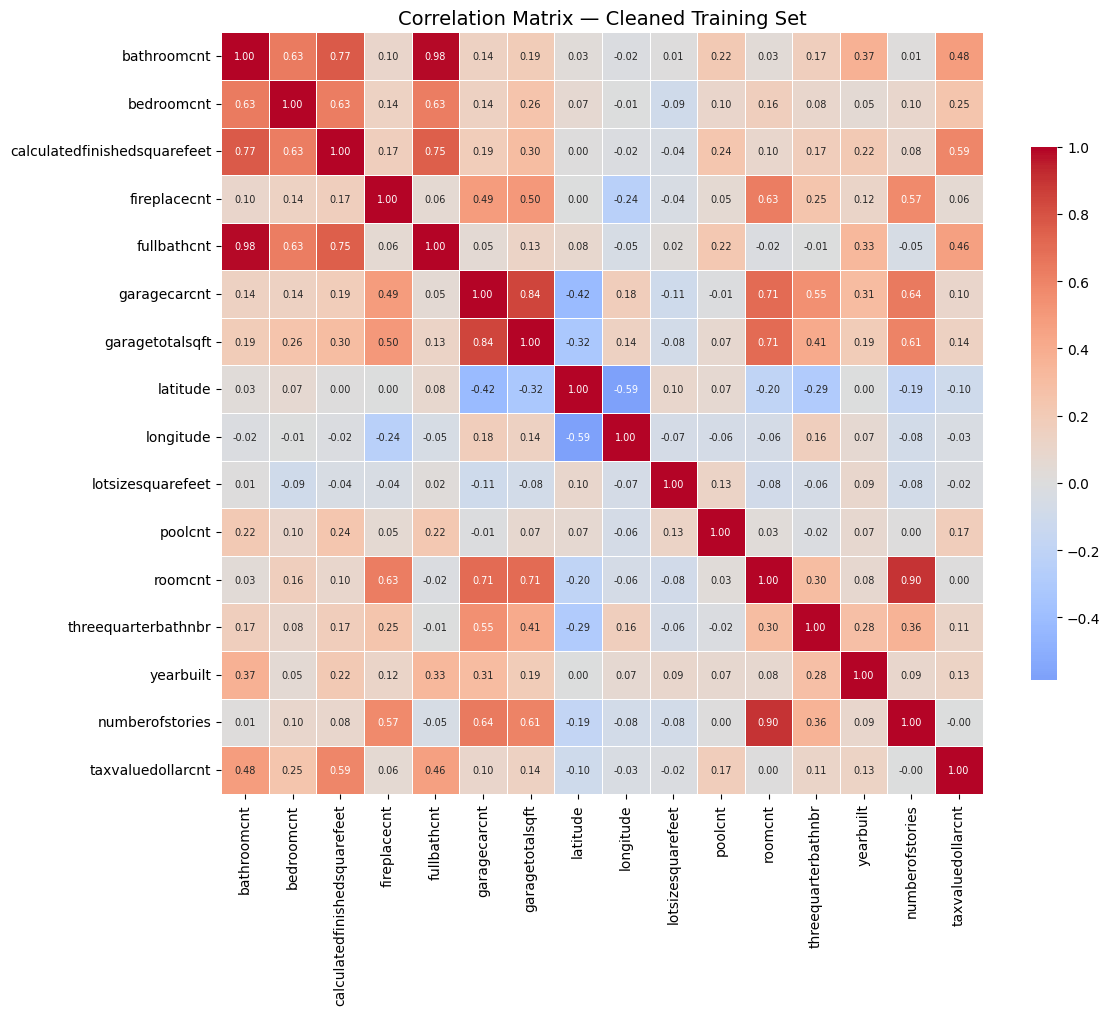

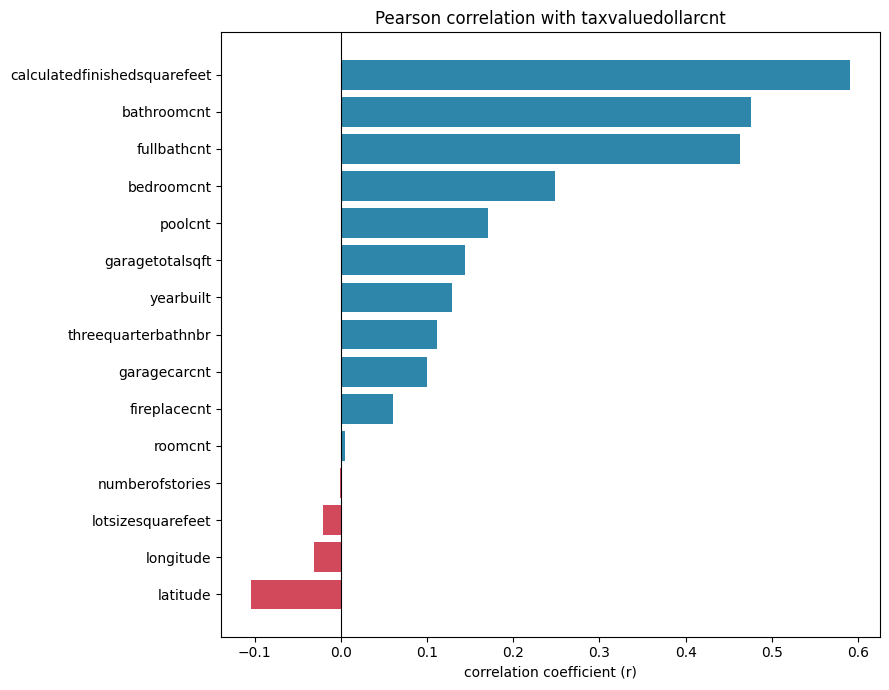


Correlation with target (ranked):
                                  r  abs_r
calculatedfinishedsquarefeet  0.591  0.591
bathroomcnt                   0.476  0.476
fullbathcnt                   0.463  0.463
bedroomcnt                    0.248  0.248
poolcnt                       0.171  0.171
garagetotalsqft               0.144  0.144
yearbuilt                     0.129  0.129
threequarterbathnbr           0.112  0.112
latitude                     -0.104  0.104
garagecarcnt                  0.100  0.100
fireplacecnt                  0.061  0.061
longitude                    -0.032  0.032
lotsizesquarefeet            -0.021  0.021
roomcnt                       0.004  0.004
numberofstories              -0.001  0.001

Highly correlated pairs (|r| > 0.8):
   feature_1       feature_2  abs_corr
 bathroomcnt     fullbathcnt  0.984905
     roomcnt numberofstories  0.898340
garagecarcnt garagetotalsqft  0.843982

Artifact check — correlation on genuinely-populated rows only:
  roomcnt vs number

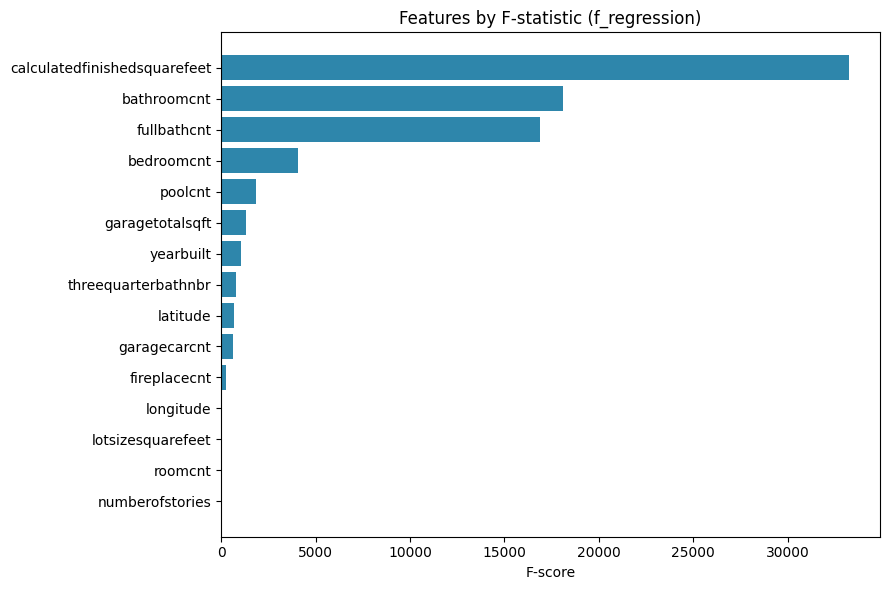


Features by F-statistic:
                              F_score  p_value
calculatedfinishedsquarefeet  33227.2   0.0000
bathroomcnt                   18116.9   0.0000
fullbathcnt                   16880.9   0.0000
bedroomcnt                     4062.8   0.0000
poolcnt                        1866.1   0.0000
garagetotalsqft                1315.3   0.0000
yearbuilt                      1044.4   0.0000
threequarterbathnbr             787.8   0.0000
latitude                        678.6   0.0000
garagecarcnt                    621.0   0.0000
fireplacecnt                    231.7   0.0000
longitude                        62.1   0.0000
lotsizesquarefeet                27.4   0.0000
roomcnt                           1.2   0.2654
numberofstories                   0.0   0.8653


In [38]:
# ============================================================
# PART 4.A — Correlation and Feature Importance
# (run on the CLEANED TRAINING SET from Part 3, per 3.D)
# ============================================================
target = 'taxvaluedollarcnt'

# Part 3.D split the target into y_train, so rejoin it for correlation analysis.
# We use ONLY the training set the test set must not influence any analysis.
df_p4 = X_train.copy()
df_p4[target] = y_train
print(f"Analysis frame (cleaned training set): {df_p4.shape}")

# --- 1. Keep only TRUE numeric measurements ---
# (b) the 585 one-hot dummy columns created in Part 3.F,
# (c) assessmentyear, which is now constant (zero variance -> undefined correlation).
categorical_coded = [
    'buildingqualitytypeid', 'fips', 'pooltypeid7', 'propertylandusetypeid',
    'regionidcounty', 'regionidneighborhood', 'censustractandblock',
    'assessmentyear',
]
ohe_prefixes = ('airconditioningtypeid_', 'heatingorsystemtypeid_',
                'unitcnt_', 'regionidcity_', 'regionidzip_')

numeric_cols = df_p4.select_dtypes(include=[np.number]).columns.tolist()
true_numeric = [c for c in numeric_cols
                if c not in categorical_coded and not c.startswith(ohe_prefixes)]
if target not in true_numeric:
    true_numeric.append(target)
print(f"Using {len(true_numeric)} true-numeric features "
      f"(excluded {len(numeric_cols) - len(true_numeric)} ID codes and one-hot dummies).")

# --- 2. Correlation matrix + heatmap (no NaNs remain after Part 3.E) ---
corr = df_p4[true_numeric].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, annot=True, fmt='.2f',
            annot_kws={'size': 7}, linewidths=0.4, cbar_kws={'shrink': 0.7})
plt.title('Correlation Matrix — Cleaned Training Set', fontsize=14)
plt.tight_layout(); plt.show()

# --- 3. Correlation with the target, ranked ---
corr_target = corr[target].drop(target).sort_values()
plt.figure(figsize=(9, 7))
colors = ['#d1495b' if v < 0 else '#2e86ab' for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color='k', lw=0.8)
plt.title(f'Pearson correlation with {target}')
plt.xlabel('correlation coefficient (r)')
plt.tight_layout(); plt.show()

print("\nCorrelation with target (ranked):")
print(pd.DataFrame({'r': corr_target.round(3),
                    'abs_r': corr_target.abs().round(3)}
                   ).sort_values('abs_r', ascending=False).to_string())

# --- 4. Highly correlated feature pairs ---
THRESH = 0.80
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.abs().stack().sort_values(ascending=False).reset_index()
pairs.columns = ['feature_1', 'feature_2', 'abs_corr']
print(f"\nHighly correlated pairs (|r| > {THRESH}):")
print(pairs[pairs.abs_corr > THRESH].to_string(index=False))

# --- 5. Imputation-artifact check ---
# Part 3.E imputed several sparse features with a constant 0. Where two features
# share the same zero-imputed rows, their correlation can be inflated by the
# imputation itself rather than by a real relationship. We re-check the top pairs
# on the subset of rows where BOTH features are non-zero (i.e. genuine values).
print("\nArtifact check — correlation on genuinely-populated rows only:")
for a, b in [('roomcnt', 'numberofstories'),
             ('garagecarcnt', 'garagetotalsqft'),
             ('bathroomcnt', 'fullbathcnt')]:
    both = df_p4[(df_p4[a] > 0) & (df_p4[b] > 0)]
    print(f"  {a} vs {b}: full r = {df_p4[a].corr(df_p4[b]):.3f}  |  "
          f"non-zero-only r = {both[a].corr(both[b]):.3f}  (n = {len(both):,})")

# --- 6. F-statistics (no NaN remain, so no imputation needed here) ---
feat_cols = [c for c in true_numeric if c != target]
F, p = f_regression(df_p4[feat_cols], df_p4[target])
f_scores = pd.Series(F, index=feat_cols).sort_values(ascending=False)
p_values = pd.Series(p, index=feat_cols)

plt.figure(figsize=(9, 6))
plt.barh(f_scores.index[::-1], f_scores.values[::-1], color='#2e86ab')
plt.title('Features by F-statistic (f_regression)')
plt.xlabel('F-score'); plt.tight_layout(); plt.show()

print("\nFeatures by F-statistic:")
print(pd.DataFrame({'F_score': f_scores.round(1),
                    'p_value': p_values.reindex(f_scores.index).round(4)}).to_string())

#### **4.A Discussion:**

Describe the strongest relationships you observed among the features and between the features and the target.

In particular, discuss:

- Which features appeared to be the strongest predictors of the target.
- Which pairs of features appeared to be highly correlated.
- Whether the correlation matrix and the F-statistics led you to similar conclusions about the most important features. Explain your reasoning.

The strongest predictors of `taxvaluedollarcnt` are the finished-living-area and bathroom features. Restricting to features with enough data to trust, the top two are `finishedsquarefeet12` (r ≈ 0.61, present on ~74k rows) and `calculatedfinishedsquarefeet` (r ≈ 0.58, ~77k rows), followed by the bathroom cluster `calculatedbathnbr`, `fullbathcnt`, and `bathroomcnt` (r ≈ 0.46–0.49, all ~77k rows). Some features show a higher correlation but on almost no data: `basementsqft` (r ≈ 0.49 on only 50 rows, 99.9% missing) and `finishedfloor1squarefeet` / `finishedsquarefeet50` (r ≈ 0.56 on ~6k rows, 92% missing) so we do not treat those as reliable signals.

> **Note:** this analysis is performed on the cleaned **training set** from Part 3 (61,953 rows), not the raw data, and excludes the one-hot dummy columns created in 3.F.


> The strongest predictor of `taxvaluedollarcnt` is `calculatedfinishedsquarefeet` (r ≈ 0.59), followed by the bathroom-count features `bathroomcnt` (0.48) and `fullbathcnt` (0.46), then `bedroomcnt` (0.25). Amenity and size features (`poolcnt` 0.17, `garagetotalsqft` 0.14, `yearbuilt` 0.13) are weakly related. `roomcnt` (0.004) and `numberofstories` (-0.001) show essentially no linear relationship with the target.


> Three pairs exceed |r| > 0.80: `bathroomcnt`-`fullbathcnt` (0.985), `roomcnt`-`numberofstories` (0.898), and `garagecarcnt`-`garagetotalsqft` (0.844). Importantly, two of these are largely **artifacts of the imputation performed in Part 3.E** rather than genuine relationships. `numberofstories` was 77% missing and imputed with a constant 0, and `roomcnt` is genuinely 0 for most records, so 76.9% of rows have both features equal to zero; restricting to rows where both are actually populated drops the correlation from 0.898 to 0.329. Similarly, `garagetotalsqft` was imputed to 0 wherever `garagecarcnt` = 0, making part of that 0.844 true by construction, on homes that actually have a garage, r falls to 0.631. Only `bathroomcnt`-`fullbathcnt` is a genuine near-duplicate (and even there, `fullbathcnt` was partly imputed *from* `bathroomcnt`).

>

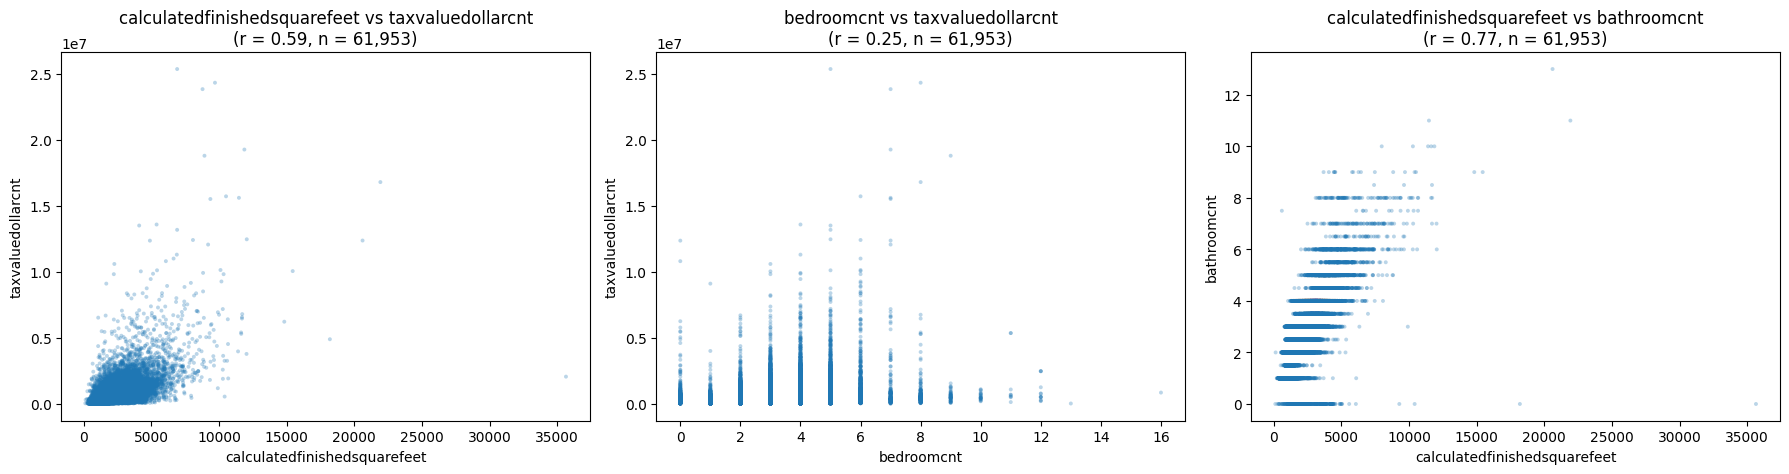

calculatedfinishedsquarefeet vs taxvaluedollarcnt: r = 0.591, n = 61,953
bedroomcnt vs taxvaluedollarcnt: r = 0.248, n = 61,953
calculatedfinishedsquarefeet vs bathroomcnt: r = 0.766, n = 61,953


In [39]:
# ============================================================
# PART 4.B — Three feature relationships (cleaned training set)
# ============================================================
pairs_to_plot = [
    ('calculatedfinishedsquarefeet', target),          # strongest predictor vs target
    ('bedroomcnt',                   target),          # discrete count vs target
    ('calculatedfinishedsquarefeet', 'bathroomcnt'),   # two correlated predictors
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, yv) in zip(axes, pairs_to_plot):
    ax.scatter(df_p4[x], df_p4[yv], s=8, alpha=0.3, edgecolor='none')
    r = df_p4[x].corr(df_p4[yv])
    ax.set_xlabel(x); ax.set_ylabel(yv)
    ax.set_title(f'{x} vs {yv}\n(r = {r:.2f}, n = {len(df_p4):,})')
plt.tight_layout(); plt.show()

for x, yv in pairs_to_plot:
    print(f"{x} vs {yv}: r = {df_p4[x].corr(df_p4[yv]):.3f}, n = {len(df_p4):,}")

#### **4.B Discussion:**

Describe what you learned from the three feature relationships you investigated.

For each pair, discuss:

- The overall pattern you observed (for example, linear, nonlinear, weak, or strong).
- What the relationship suggests about the features and their potential usefulness for predicting the target.
- Whether your observations suggest possible feature engineering or preprocessing ideas that could be investigated in **Milestone 2**.

> **`calculatedfinishedsquarefeet` vs `taxvaluedollarcnt` (r ≈ 0.59, n = 61,953):** a strong, roughly linear positive relationship, larger finished living area means higher assessed value. The vertical spread widens noticeably as square footage increases (the points fan outward), which is classic heteroskedasticity and suggests that a log transform of the target and/or the feature could stabilize the variance and improve a linear model in Milestone 2. This is the single most useful predictor remaining after cleaning.

>

> **`bedroomcnt` vs `taxvaluedollarcnt` (r ≈ 0.25, n = 61,953):** a weak, clearly stepped relationship, as expected for a discrete count. Value rises with bedrooms through the low and middle range but flattens and becomes noisy at the high end, where extreme bedroom counts likely reflect data-entry errors or unusual multi-unit properties. On its own it is a weak predictor, but it may become useful as an interaction term (for example bedrooms relative to square footage) or after outlier handling, which Part 3.C deliberately deferred to Milestone 2.

>

> **`calculatedfinishedsquarefeet` vs `bathroomcnt` (r ≈ 0.77, n = 61,953):** a strong positive relationship between two predictors — bigger homes have more bathrooms. This sits just below our 0.80 flagging threshold but still represents meaningful redundancy between the two strongest predictors in the dataset. It suggests testing in Milestone 2 whether both features should be retained, or whether a derived feature such as bathrooms-per-square-foot captures the signal more efficiently while reducing multicollinearity. All of these remain hypotheses to evaluate experimentally, not changes to make now.

## Part 5: Investigate Potential Feature Engineering [6 pts]

In this part, you will identify potential feature engineering and preprocessing techniques that **may** improve model performance.

The goal is to develop hypotheses based on your exploratory data analysis—not to permanently modify the dataset. In **Milestone 2**, you will evaluate these ideas experimentally and determine whether they actually improve the model.

**Important:** Do **not** permanently transform, remove, or add features in this milestone.

## Part 5.A: Identify Potential Feature Engineering Opportunities

Based on your exploratory analysis, identify **at least three (3)** feature engineering or preprocessing techniques that you believe may improve model performance.

Possible ideas include (but are not limited to):

- Log transformations
- Scaling or normalization
- Removing highly correlated features
- Polynomial features
- Interaction features
- Binning continuous variables
- Outlier removal
- Combining or aggregating existing features

You may investigate these ideas by creating visualizations or performing exploratory analyses, but **do not permanently modify the dataset**.

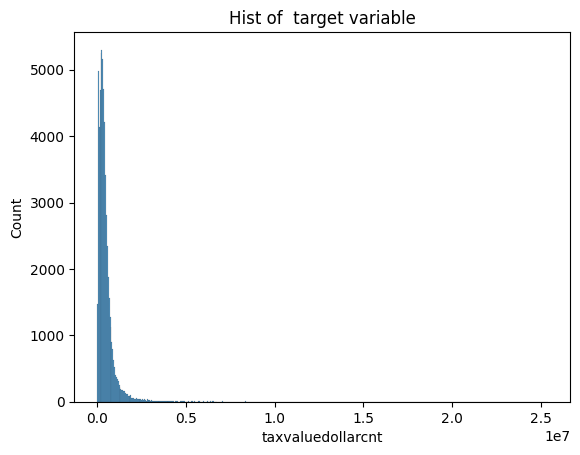

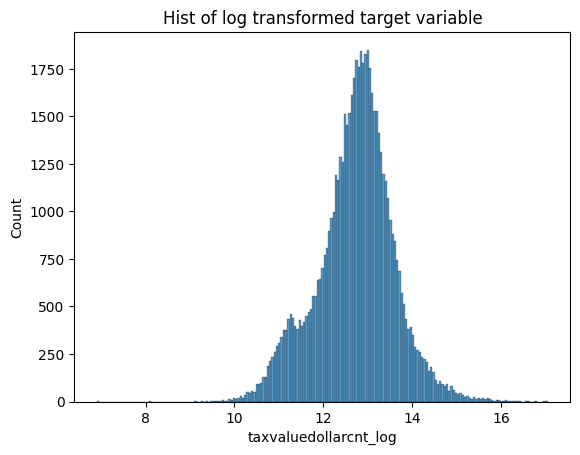

<Axes: ylabel='taxvaluedollarcnt_log'>

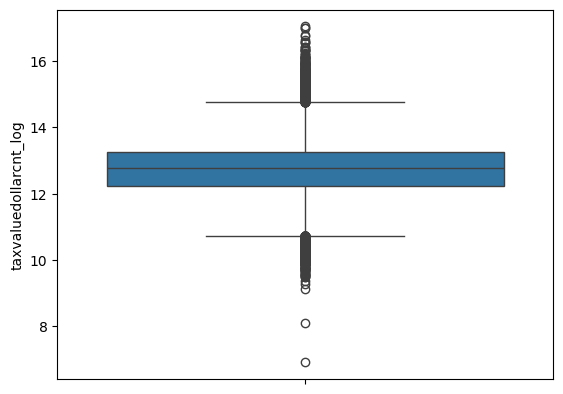

In [40]:
df_fe = pd.concat((X_train,y_train), axis= 0)
df_fe['taxvaluedollarcnt_log'] = np.log(df_fe['taxvaluedollarcnt'])
sns.histplot(df_fe['taxvaluedollarcnt'])
plt.title('Hist of  target variable')
plt.show()
sns.histplot(df_fe['taxvaluedollarcnt_log'])
plt.title('Hist of log transformed target variable')
plt.show()
sns.boxplot(df_fe['taxvaluedollarcnt_log'])

Text(0.5, 1.0, 'Hist roomsize(finished sqft/room count)')

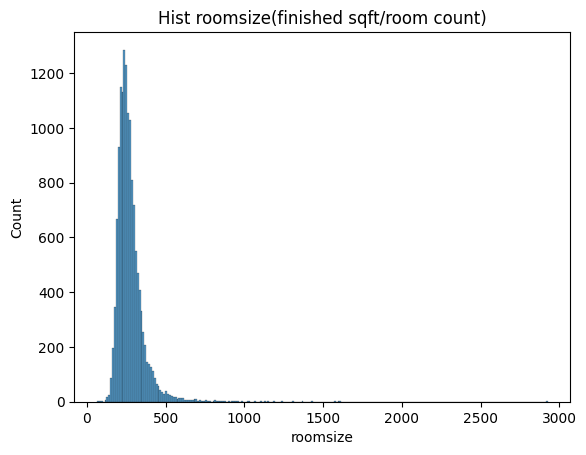

In [41]:
df_fe['roomsize'] = df_fe['calculatedfinishedsquarefeet']/df_fe['roomcnt']
sns.histplot(df_fe['roomsize'])
plt.title('Hist roomsize(finished sqft/room count)')

In [42]:
print(f'Correlation Full bathroom count vs bathroom count: {df_fe['fullbathcnt'].corr(df_fe['bathroomcnt'])}')
print(f'Correlation Room count vs Number of stories: {df_fe['roomcnt'].corr(df_fe['numberofstories'])}')

Correlation Full bathroom count vs bathroom count: 0.9849054074703294
Correlation Room count vs Number of stories: 0.8983396298716628


#### **5.A Discussion:**

Describe the three feature engineering or preprocessing ideas you identified.

For each one, explain:

- Which feature(s) it would affect.
- Why you believe it may improve model performance.
- How you would determine in **Milestone 2** whether it actually improves the model (for example, by comparing appropriate evaluation metrics on a validation or test set).

> **Target Variable Log transformation - taxassessed value** : Early on we see that there is a large range of values for the target value. The distriubtion if heavily right skewed. Heavily skewed data can make make models perform poorly due the the exagerated prescense of outliers. One might propose removing outliers, but analysis of the dataset reveals the homes to be located in Southern California, where some of the most expensive real estate exist. Normally these high values might be written off as erroreous data, but given the context likely represent ultra high value properties. A log transfomration of the target variable compresses the values such that the outliers are not as extreme. Outliers will continue to exist in the data, but their inclusion or exclusion will be determined next milestone.

> **Aggregate Measure - Room size (Finishedsqfeet/roomcount)**  : One aggregate measure that might be worth exploring is average room size given by the finished square feet of the home divided by the home's room count. This metric can be informative of what type of style home is represented. For example open concept homes usually have fewer large rooms compared to more traditional layouts. This additional predescribed interaction between features could help a model capture information on the assessed tax value. There may be some difficulties with this metric as finishedsqfeet is a highly right skewed, corressponding with the presences of ultra high value properities present in southern California. The finishedsqfeet feature may have to be normalized prior. 

> **Removal of highly correlated features - Full bathroom count and bathroom count; Room count and number of stories** : A few highly correlated features have already been removed, variations of finished square feet of the home. EDA has shown that Full bathroom count and bathroom count are nearly competely correlated, pearson's correlation coefficient of 0.985. While more surprisingly, there is a quite a strong correlation between the room count and the number of stories in a home, pearson's correlation coefficient of 0.898. Removing highly correlated features reduces the possible multicollinearity which would otherwise cause a model to exaggerate the effects of redundant information. Given the F-regression values calcuated Full bathroom count and number of stories are likely the worse predictors of the target variable and better suited for removal. 

> To evaluate each change, the model will be run both with and without the proposed change. Error metrics will then be evaluated to see if the presence or abscense of a given change improves the model's predictive ability.

> In the case of transforming the target value, the model using the log transformed value, the prediction value will be log transformed so for proper comparison the predicted value will have to be converted by raising 10 to the predicted value, given a base 10 log transformation. Mean abolute percentage error can serve as a good regression metric as it helps standardized the error between the grossly differently priced homes present in the data. Mean absolute error can be another metric to analyze as it also generally has low impacts from outliers, but avoids the unequal effects of a given change in value, under predicted values get exaggerated while over predicted values are minimized. 

> For the aggregate measure - room size, beyond testing for if mean absolute error is improved with the addition of this new metric, the coefficent of the linear model term can be examined. A large coefficent would imply that this engineered feature captures information relevant and impactful to the model. 

> Finally for the removal of highly correlated features, beyond testing if mean absolute error is decreased by removing these features, Variance inflation factor(VIF) is improved by the removal of the highly correlated features. 

## Part 5.B: Prioritize Your Ideas

Not all feature engineering ideas are equally promising.

Based on your investigation, select the **two** ideas you believe are most likely to improve model performance.

Briefly explain why you selected these ideas over the others.

No code is required for this section.

#### **5.B Discussion:**

Suppose you had time to evaluate only **two** feature engineering or preprocessing ideas in **Milestone 2**.

For each one, explain:

- Which idea you would prioritize.
- Why you believe it is the most promising.
- What evidence from your exploratory analysis (such as feature distributions, missing values, feature relationships, or other observations) led you to this conclusion.

> Priority 1: target variable log transformation 
> The behavior of the target variable will ultimately play the largest role in a model's ability to learn. Since the baseline target is heavily right skewed by values representing the ultra luxury properites in Southern California and not errors it is difficult to remove them wholeheartedly. One could argue that these are special case properties that warrant special modeling, and that a modeling for a "normal" property will always struggle with these properties. 

> Priority 2: removal of highly correlated features
> Linear regression models are quite sensitive to multicollinearity; it can make it difficult to attribute the weight of each feature as it contributes to the target value. From the EDA, it is seen that there is a Pearson's correlation of 0.985 between Full bathroom count and bathroom count, meaning they are virtually identical, and the Pearson's correlation coefficent of 0.898 between room count and number of stories. The latter is still highly correlated and potentially represents redundant information to the model. 

#### **5 Discussion:** 

Describe in a paragraph why you chose these transformations and what you observed. 


## **Appendix 1: Features of the Zillow Dataset**  

0. **parcelid**: Unique identifier for the property parcel.  
1. **airconditioningtypeid**: Identifier for the type of air conditioning installed.  
2. **architecturalstyletypeid**: Identifier for the architectural style of the property.  
3. **basementsqft**: Square footage of the basement.  
4. **bathroomcnt**: Number of bathrooms.  
5. **bedroomcnt**: Number of bedrooms.  
6. **buildingclasstypeid**: Identifier for the building framing type (e.g., wood frame, steel frame).  
7. **buildingqualitytypeid**: Numeric value indicating the quality of the building (higher values often indicate better quality).  
8. **calculatedbathnbr**: Calculated number of bathrooms, including fractional bathrooms.  
9. **decktypeid**: Identifier for the type of deck.  
10. **finishedfloor1squarefeet**: Square footage of the finished area on the first floor.  
11. **calculatedfinishedsquarefeet**: Total finished living area square footage.  
12. **finishedsquarefeet12**: Finished living area square footage.  
13. **finishedsquarefeet13**: Perimeter living area square footage.  
14. **finishedsquarefeet15**: Total area.  
15. **finishedsquarefeet50**: Square footage of the finished area on the upper floors.  
16. **finishedsquarefeet6**: Base unfinished and finished area square footage.  
17. **fips**: Federal Information Processing Standards code, uniquely identifying counties and county equivalents.  
18. **fireplacecnt**: Number of fireplaces.  
19. **fullbathcnt**: Number of full bathrooms.  
20. **garagecarcnt**: Number of cars that can fit in the garage.  
21. **garagetotalsqft**: Total square footage of the garage.  
22. **hashottuborspa**: Indicates if the property has a hot tub or spa.  
23. **heatingorsystemtypeid**: Identifier for the type of heating system.  
24. **latitude**: Latitude coordinate of the property.  
25. **longitude**: Longitude coordinate of the property.  
26. **lotsizesquarefeet**: Lot size in square feet.  
27. **poolcnt**: Number of pools on the property.  
28. **poolsizesum**: Total square footage of all pools.  
29. **pooltypeid10**: Identifier for spa or hot tub.  
30. **pooltypeid2**: Identifier for pool with spa or hot tub.  
31. **pooltypeid7**: Identifier for pool without hot tub or spa.  
32. **propertycountylandusecode**: County land use code for the property.  
33. **propertylandusetypeid**: Identifier for the property land use type.  
34. **propertyzoningdesc**: Description of the property's zoning.  
35. **rawcensustractandblock**: Unprocessed census tract and block identifier.  
36. **regionidcity**: Identifier for the city.  
37. **regionidcounty**: Identifier for the county.  
38. **regionidneighborhood**: Identifier for the neighborhood.  
39. **regionidzip**: Identifier for the ZIP code.  
40. **roomcnt**: Total number of rooms.  
41. **storytypeid**: Identifier for the type of stories in the building (e.g., basement, attic).  
42. **threequarterbathnbr**: Number of 3/4 bathrooms (typically includes a shower but no tub).  
43. **typeconstructiontypeid**: Identifier for the type of construction (e.g., frame, masonry).  
44. **unitcnt**: Number of units in the building (e.g., for multi-family properties).  
45. **yardbuildingsqft17**: Square footage of the 17th yard building (e.g., shed).  
46. **yardbuildingsqft26**: Square footage of the 26th yard building.  
47. **yearbuilt**: Year the property was built.  
48. **numberofstories**: Number of stories in the building.  
49. **fireplaceflag**: Indicates if the property has a fireplace.  
50. **assessmentyear**: Year the property was assessed.  
51. **taxdelinquencyflag**: Indicates whether the property’s taxes are delinquent. Often “Y” if taxes are past due; otherwise null/empty.  
52. **taxdelinquencyyear**: The year in which the property’s taxes became delinquent.  
53. **censustractandblock**: A combined identifier for the property’s census tract and block group (part of the U.S. Census geographic hierarchy).  
54. **taxvaluedollarcnt**: Total assessed value of the property (land plus structure) in dollars.  


## Appendix 2: Summary of Basic Imputation Methods
Imputation depends on the data type and context. Below are common techniques for handling missing values.

---

### **1. Simple Imputation (Basic Methods)**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Drop Missing Values** | Few missing values (<5% of data) | `df.dropna()` | Quick and easy | Can remove valuable data |
| **Mean Imputation** | Normally distributed numerical data | `df.fillna(df.mean())` | Preserves mean; simple | Distorts variance, weak for skewed data |
| **Median Imputation** | Skewed numerical data | `df.fillna(df.median())` | Robust to outliers | May not capture patterns |
| **Mode Imputation** | Categorical features | `df.fillna(df.mode().iloc[0])` | Keeps most common category | Can introduce bias |
| **Constant Value (e.g., 0)** | Special cases (e.g., unknown numerical data) | `df.fillna(0)` | Simple and interpretable | Can mislead model |
| **"Unknown" Category Imputation** (**New Addition**) | Categorical features with missing values | `df.fillna('Unknown')` | Keeps all rows, prevents data loss | May introduce artificial category |

---

### **2. Statistical & Advanced Imputation**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Interpolation** | Time series, ordered data | `df.interpolate(method='linear')` | Preserves trends | May not work for non-continuous data |
| **K-Nearest Neighbors (KNN)** | Small datasets, patterns in features | `KNNImputer(n_neighbors=5).fit_transform(df)` | Uses similar observations | Computationally expensive |
| **Multivariate Imputation (MICE)** | Complex relationships between variables | `IterativeImputer().fit_transform(df)` | Captures relationships | Slower than mean/median |
| **Regression Imputation** | When missing values depend on other variables | Train regression model to predict missing values | More accurate than mean/median | Risk of overfitting |

---

### **When to Use "Unknown" Category for Categorical Imputation**
✅ **Good for:**
- Categorical features where missing values may indicate meaningful differences.  
- Customer data (e.g., missing survey responses → "No Response").  
- Product categories where missing could be a separate group.  

❌ **Avoid if:**
- The missing category does **not** have a meaningful interpretation.
- The model might learn spurious patterns from an artificial category.

---

### **Which Method to Choose?**
| Scenario | Best Method |
|----------|------------|
| **Few missing values (<5%)** | Drop NaNs (`df.dropna()`) |
| **Numerical & normal distribution** | Mean (`df.fillna(df.mean())`) |
| **Numerical & skewed distribution** | Median (`df.fillna(df.median())`) |
| **Categorical features** | Mode (`df.fillna(df.mode().iloc[0])`) |
| **Categorical with possible meaning in missingness** | "Unknown" Category (`df.fillna('Unknown')`) |
| **Small dataset with patterns** | KNN Imputer (`KNNImputer()`) |
| **Complex relationships between features** | MICE / Iterative Imputer |



## Appendix 3: Flowchart for Identifying Feature Types

The following flowchart can help you identify the statistical type of each feature and determine an appropriate encoding strategy for categorical variables.

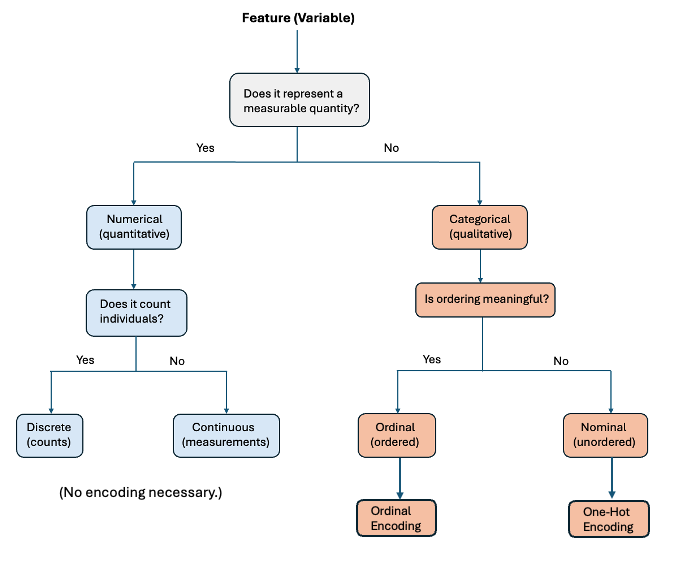